In [ ]:
import os
import tensorflow as tf
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Dataset location from Assignment 1
dataset_path = '/content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification'

# Verify dataset access
print("TensorFlow version:", tf.__version__)
print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Dataset contents:", os.listdir(dataset_path))

Mounted at /content/drive
TensorFlow version: 2.21.0
Dataset exists: True
Dataset contents: ['dataset_info.csv', 'test', 'train', 'validation']


In [ ]:
import os

dataset_path = '/content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification'

total_images = 0

for split in ['train', 'validation', 'test']:
    print(f"\n{split.upper()} DATASET")

    split_total = 0

    for category in ['cats', 'dogs']:
        folder = os.path.join(dataset_path, split, category)

        if os.path.exists(folder):
            images = [
                f for f in os.listdir(folder)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))
            ]

            print(f"{category}: {len(images)} images")
            split_total += len(images)
        else:
            print(f"{category}: Folder not found")

    print(f"Total {split}: {split_total}")
    total_images += split_total

print("\nTOTAL AVAILABLE IMAGES:", total_images)

print("\nREQUIRED MIDTERM SPLIT")
print("70% Training:", round(total_images * 0.70))
print("30% Testing:", total_images - round(total_images * 0.70))


TRAIN DATASET
cats: 9977 images
dogs: 9966 images
Total train: 19943

VALIDATION DATASET
cats: 1247 images
dogs: 1245 images
Total validation: 2492

TEST DATASET
cats: 1248 images
dogs: 1247 images
Total test: 2495

TOTAL AVAILABLE IMAGES: 24930

REQUIRED MIDTERM SPLIT
70% Training: 17451
30% Testing: 7479


In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

dataset_path = '/content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification'

records = []

for split in ['train', 'validation', 'test']:
    for category in ['cats', 'dogs']:
        folder = os.path.join(dataset_path, split, category)

        for filename in sorted(os.listdir(folder)):
            if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
                records.append({
                    'filepath': os.path.join(folder, filename),
                    'label': 0 if category == 'cats' else 1
                })

df = pd.DataFrame(records)

# Check for duplicate file paths
assert not df['filepath'].duplicated().any()

# Stratified 70/30 split
train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df['label']
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Save to Google Drive for reproducibility
save_path = '/content/drive/MyDrive/Applied_AI_Midterm'
os.makedirs(save_path, exist_ok=True)

train_df.to_csv(os.path.join(save_path, 'train_split.csv'), index=False)
test_df.to_csv(os.path.join(save_path, 'test_split.csv'), index=False)

print("Total images:", len(df))
print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nTraining class distribution:")
print(train_df['label'].value_counts().sort_index())

print("\nTesting class distribution:")
print(test_df['label'].value_counts().sort_index())

print("\nSplit files saved successfully!")

Total images: 24930
Training images: 17451
Testing images: 7479

Training class distribution:
label
0    8730
1    8721
Name: count, dtype: int64

Testing class distribution:
label
0    3742
1    3737
Name: count, dtype: int64

Split files saved successfully!


In [ ]:
import hashlib
from PIL import Image
from tqdm.auto import tqdm

def check_dataset(df, name):
    hashes = []
    invalid_files = []

    for path in tqdm(df['filepath'], desc=f"Checking {name}"):
        try:
            # Check image readability
            with Image.open(path) as img:
                img.verify()

            # Calculate file hash
            with open(path, 'rb') as f:
                file_hash = hashlib.sha256(f.read()).hexdigest()

            hashes.append(file_hash)

        except Exception as e:
            invalid_files.append((path, str(e)))
            hashes.append(None)

    return hashes, invalid_files

train_hashes, train_invalid = check_dataset(train_df, "Training")
test_hashes, test_invalid = check_dataset(test_df, "Testing")

train_hash_set = set(train_hashes) - {None}
test_hash_set = set(test_hashes) - {None}

overlap = train_hash_set.intersection(test_hash_set)

print("\n===== DATASET INTEGRITY CHECK =====")
print("Invalid training images:", len(train_invalid))
print("Invalid testing images:", len(test_invalid))
print("Duplicate contents across train/test:", len(overlap))
print("Duplicate contents within training:",
      len(train_hash_set) != len([h for h in train_hashes if h is not None]))
print("Duplicate contents within testing:",
      len(test_hash_set) != len([h for h in test_hashes if h is not None]))

Checking Training:   0%|          | 0/17451 [00:00<?, ?it/s]

Checking Testing:   0%|          | 0/7479 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



===== DATASET INTEGRITY CHECK =====
Invalid training images: 0
Invalid testing images: 0
Duplicate contents across train/test: 0
Duplicate contents within training: False
Duplicate contents within testing: False


In [ ]:
import os
import pickle

save_path = '/content/drive/MyDrive/Applied_AI_Midterm'
os.makedirs(save_path, exist_ok=True)

verification_results = {
    'train_hashes': train_hashes,
    'test_hashes': test_hashes,
    'train_invalid': train_invalid,
    'test_invalid': test_invalid
}

verification_file = os.path.join(
    save_path,
    'dataset_verification.pkl'
)

with open(verification_file, 'wb') as f:
    pickle.dump(verification_results, f)

# Confirm the file was saved successfully
assert os.path.isfile(verification_file)

print("Verification results saved successfully!")
print("File:", verification_file)
print("File size:", os.path.getsize(verification_file), "bytes")

Verification results saved successfully!
File: /content/drive/MyDrive/Applied_AI_Midterm/dataset_verification.pkl
File size: 1670671 bytes


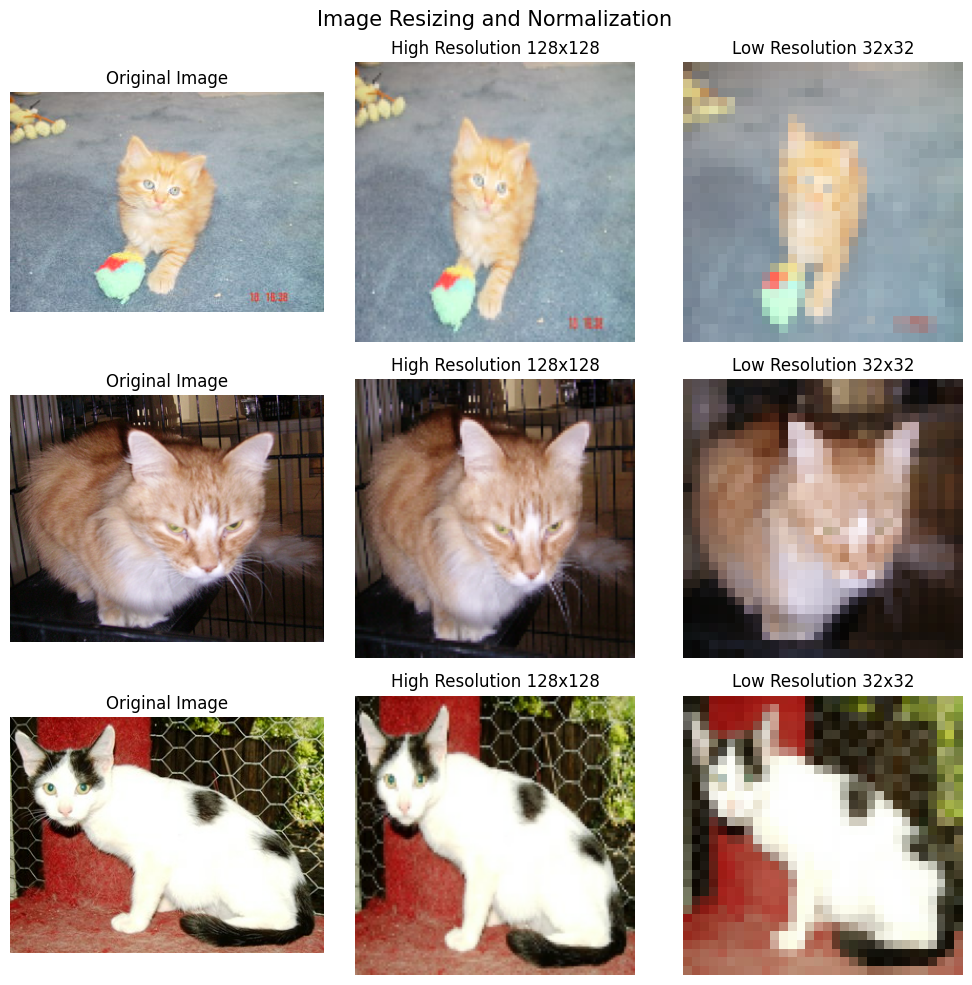

Normalization range: [0, 1]
High-resolution shape: (128, 128, 3)
Low-resolution shape: (32, 32, 3)


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Image resolutions
HR_SIZE = 128
LR_SIZE = 32

# Select 3 reproducible training samples
sample_df = train_df.sample(n=3, random_state=42)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, (_, row) in enumerate(sample_df.iterrows()):

    # Read and decode original image
    image_bytes = tf.io.read_file(row['filepath'])
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    # Convert pixel values to [0, 1]
    image = tf.image.convert_image_dtype(image, tf.float32)

    # Resize to high resolution (128x128)
    hr_image = tf.image.resize(image, [HR_SIZE, HR_SIZE])

    # Create low resolution (32x32)
    lr_image = tf.image.resize(
        hr_image, [LR_SIZE, LR_SIZE],
        method='area'
    )

    # Display original, HR and LR images
    images = [image, hr_image, lr_image]
    titles = [
        'Original Image',
        'High Resolution 128x128',
        'Low Resolution 32x32'
    ]

    for j in range(3):
        axes[i, j].imshow(
            tf.clip_by_value(images[j], 0, 1).numpy()
        )
        axes[i, j].set_title(titles[j])
        axes[i, j].axis('off')

plt.suptitle(
    'Image Resizing and Normalization',
    fontsize=15
)
plt.tight_layout()
plt.show()

print("Normalization range: [0, 1]")
print("High-resolution shape:", hr_image.shape)
print("Low-resolution shape:", lr_image.shape)

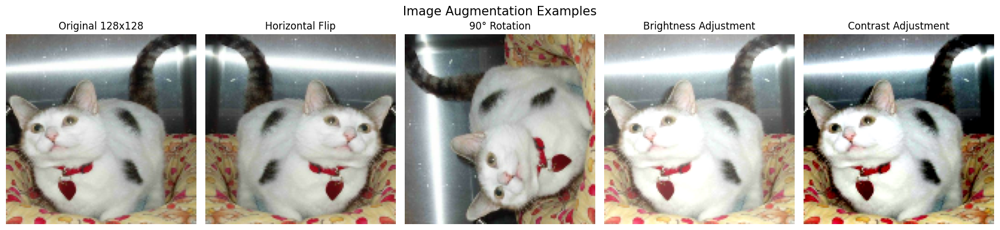

Original pixel range: 0.0 1.0
Augmentation visualization completed!


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Select one reproducible training image
sample_path = train_df.iloc[0]['filepath']

image_bytes = tf.io.read_file(sample_path)
image = tf.io.decode_image(
    image_bytes,
    channels=3,
    expand_animations=False
)
image.set_shape([None, None, 3])

# Normalize and resize to 128x128
image = tf.image.convert_image_dtype(image, tf.float32)
image = tf.image.resize(image, [128, 128])
image = tf.clip_by_value(image, 0.0, 1.0)

# Four augmentation methods
flipped = tf.image.flip_left_right(image)

rotated = tf.image.rot90(image, k=1)

brightened = tf.image.adjust_brightness(image, delta=0.2)
brightened = tf.clip_by_value(brightened, 0.0, 1.0)

contrasted = tf.image.adjust_contrast(image, contrast_factor=1.5)
contrasted = tf.clip_by_value(contrasted, 0.0, 1.0)

# Display transformations
images = [image, flipped, rotated, brightened, contrasted]
titles = [
    "Original 128x128",
    "Horizontal Flip",
    "90° Rotation",
    "Brightness Adjustment",
    "Contrast Adjustment"
]

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.numpy())
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("Image Augmentation Examples", fontsize=15)
plt.tight_layout()
plt.show()

print("Original pixel range:",
      float(tf.reduce_min(image)),
      float(tf.reduce_max(image)))

print("Augmentation visualization completed!")

In [ ]:

import tensorflow as tf
import numpy as np

# ==========================================
# STEP 4.1: DATA LOADING AND PREPROCESSING
# ==========================================

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Image and batch settings
IMG_SIZE = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# ------------------------------------------
# 1. Data augmentation
# ------------------------------------------

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomContrast(0.1)
], name="data_augmentation")


# ------------------------------------------
# 2. Image loading and normalization
# ------------------------------------------

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize image to 128x128
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Normalize pixel values to [0, 1]
    image = tf.cast(image, tf.float32) / 255.0

    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, tf.cast(label, tf.float32)


# ------------------------------------------
# 3. Create training and testing datasets
# ------------------------------------------

def create_dataset(dataframe, training=False):

    paths = dataframe['filepath'].astype(str).values
    labels = dataframe['label'].astype('float32').values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    # Shuffle training images only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Load and preprocess images
    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    # Create batches
    dataset = dataset.batch(BATCH_SIZE)

    # Apply augmentation to training data only
    if training:
        dataset = dataset.map(
            lambda images, labels: (
                tf.clip_by_value(
                    data_augmentation(
                        images,
                        training=True
                    ),
                    0.0,
                    1.0
                ),
                labels
            ),
            num_parallel_calls=AUTOTUNE
        )

    # Improve loading performance
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# ------------------------------------------
# 4. Create datasets
# ------------------------------------------

train_dataset = create_dataset(
    train_df,
    training=True
)

test_dataset = create_dataset(
    test_df,
    training=False
)


# ------------------------------------------
# 5. Verify output
# ------------------------------------------

images, labels = next(iter(train_dataset))

print("===== DATA PIPELINE VERIFICATION =====")

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print(
    "Pixel range:",
    float(tf.reduce_min(images)),
    float(tf.reduce_max(images))
)

print("Sample labels:", labels[:10].numpy())

# Verify normalization
assert float(tf.reduce_min(images)) >= 0.0
assert float(tf.reduce_max(images)) <= 1.0

print("\nData pipeline created successfully!")
print("All pixel values are within [0, 1].")


===== DATA PIPELINE VERIFICATION =====
Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Pixel range: 0.0 1.0
Sample labels: [1. 0. 0. 0. 0. 1. 0. 0. 1. 1.]

Data pipeline created successfully!
All pixel values are within [0, 1].


In [ ]:

from sklearn.model_selection import train_test_split
import os

# Split only the existing training portion.
# The 30% test set remains untouched.

model_train_df, val_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=42,
    stratify=train_df["label"]
)

model_train_df = model_train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# Create datasets using our corrected pipeline
train_dataset = create_dataset(
    model_train_df,
    training=True
)

val_dataset = create_dataset(
    val_df,
    training=False
)

test_dataset = create_dataset(
    test_df,
    training=False
)

# Save the new split information
save_path = "/content/drive/MyDrive/Applied_AI_Midterm"

model_train_df.to_csv(
    os.path.join(save_path, "model_train_split.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(save_path, "validation_split.csv"),
    index=False
)

print("===== FINAL DATASET DISTRIBUTION =====")
print("Training:", len(model_train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(model_train_df) + len(val_df) + len(test_df))

print("\nTraining class distribution:")
print(model_train_df["label"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df["label"].value_counts().sort_index())

print("\nValidation split saved successfully!")


===== FINAL DATASET DISTRIBUTION =====
Training: 15705
Validation: 1746
Testing: 7479
Total: 24930

Training class distribution:
label
0    7857
1    7848
Name: count, dtype: int64

Validation class distribution:
label
0    873
1    873
Name: count, dtype: int64

Validation split saved successfully!


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# STEP 5.1: BUILD MODEL A - MOBILENETV2
# ==========================================

tf.keras.utils.set_random_seed(42)

# 1. Load pretrained MobileNetV2
base_model_A = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

# 2. Freeze pretrained layers
base_model_A.trainable = False

# 3. Define input
inputs_A = layers.Input(shape=(128, 128, 3))

# 4. Convert normalized [0, 1] input
# to MobileNetV2's expected [-1, 1] range
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(inputs_A)

# 5. Extract pretrained image features
x = base_model_A(x, training=False)

# 6. Add binary classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs_A = layers.Dense(
    1,
    activation="sigmoid"
)(x)

# 7. Create Model A
model_A = Model(
    inputs=inputs_A,
    outputs=outputs_A,
    name="Model_A_MobileNetV2"
)

# 8. Compile
model_A.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 9. Display architecture
model_A.summary()

print("\nModel A created successfully!")
print("Input shape:", model_A.input_shape)
print("Output shape:", model_A.output_shape)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Model_A_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Model A created successfully!
Input shape: (None, 128, 128, 3)
Output shape: (None, 1)


In [ ]:

import tensorflow as tf
import numpy as np

# ==========================================
# STEP 5.2: TEST MODEL A FORWARD PASS
# ==========================================

# Get one batch from the training dataset
sample_images, sample_labels = next(iter(train_dataset))

# Generate predictions
predictions = model_A(sample_images, training=False)

# Convert probabilities to predicted classes
predicted_classes = (
    predictions.numpy().flatten() >= 0.5
).astype(int)

print("===== MODEL A FORWARD PASS TEST =====")

print("Input images shape:", sample_images.shape)
print("Predictions shape:", predictions.shape)

print("\nFirst 10 predicted probabilities:")
print(np.round(predictions.numpy().flatten()[:10], 4))

print("\nFirst 10 predicted classes:")
print(predicted_classes[:10])

print("\nFirst 10 actual labels:")
print(sample_labels.numpy()[:10].astype(int))

# Verify output dimensions and probabilities
assert predictions.shape == (len(sample_images), 1)
assert np.all(np.isfinite(predictions.numpy()))
assert np.all(predictions.numpy() >= 0)
assert np.all(predictions.numpy() <= 1)

print("\nModel A forward pass completed successfully!")


===== MODEL A FORWARD PASS TEST =====
Input images shape: (32, 128, 128, 3)
Predictions shape: (32, 1)

First 10 predicted probabilities:
[0.348  0.3118 0.2924 0.6979 0.1816 0.1642 0.6448 0.4315 0.4385 0.1778]

First 10 predicted classes:
[0 0 0 1 0 0 1 0 0 0]

First 10 actual labels:
[0 1 1 1 1 0 1 0 0 0]

Model A forward pass completed successfully!


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# STEP 6.1: SRGAN GENERATOR
# ==========================================

tf.keras.utils.set_random_seed(42)

# Residual block
def residual_block(x, filters=64):
    shortcut = x

    y = layers.Conv2D(
        filters, 3, padding="same"
    )(x)
    y = layers.BatchNormalization()(y)
    y = layers.PReLU(shared_axes=[1, 2])(y)

    y = layers.Conv2D(
        filters, 3, padding="same"
    )(y)
    y = layers.BatchNormalization()(y)

    return layers.Add()([shortcut, y])


# Upsampling block (2x)
def upsample_block(x, filters=256):
    x = layers.Conv2D(
        filters, 3, padding="same"
    )(x)

    # Pixel shuffle: 4 channels become 2x2 pixels
    x = layers.Lambda(
        lambda t: tf.nn.depth_to_space(t, 2)
    )(x)

    x = layers.PReLU(shared_axes=[1, 2])(x)
    return x


# Build generator
def build_generator(num_residual_blocks=8):

    inputs = layers.Input(shape=(32, 32, 3))

    # Initial feature extraction
    x = layers.Conv2D(
        64, 9, padding="same"
    )(inputs)
    x = layers.PReLU(shared_axes=[1, 2])(x)

    long_skip = x

    # Residual learning
    for _ in range(num_residual_blocks):
        x = residual_block(x)

    x = layers.Conv2D(
        64, 3, padding="same"
    )(x)
    x = layers.BatchNormalization()(x)

    x = layers.Add()([x, long_skip])

    # Upscale 32 -> 64 -> 128
    x = upsample_block(x)
    x = upsample_block(x)

    # Final RGB output in [0, 1]
    outputs = layers.Conv2D(
        3, 9,
        padding="same",
        activation="sigmoid"
    )(x)

    return Model(
        inputs,
        outputs,
        name="SRGAN_Generator"
    )


generator = build_generator()

generator.summary()

print("\nSRGAN Generator created successfully!")
print("Input shape:", generator.input_shape)
print("Output shape:", generator.output_shape)
print("Total parameters:", generator.count_params())


Model: "SRGAN_Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │     15,616 │ input_layer_4[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu (PReLU)     │ (None, 32, 32,    │         64 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     36,928 │ p_re_lu[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_1 (PReLU)   │ (None, 32, 32,    │         64 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     36,928 │ p_re_lu_1[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ p_re_lu[0][0],    │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,928 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_2 (PReLU)   │ (None, 32, 32,    │         64 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     36,928 │ p_re_lu_2[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 32, 32,    │          0 │ add[0][0],        │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │     36,928 │ add_1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_5[0][0]  

 Total params: 959,427 (3.66 MB)

 Trainable params: 957,251 (3.65 MB)

 Non-trainable params: 2,176 (8.50 KB)


SRGAN Generator created successfully!
Input shape: (None, 32, 32, 3)
Output shape: (None, 128, 128, 3)
Total parameters: 959427


===== GENERATOR FORWARD PASS TEST =====
Low-resolution input shape: (2, 32, 32, 3)
Generated output shape: (2, 128, 128, 3)
Target image shape: (2, 128, 128, 3)
Generated pixel range: 0.4231317937374115 0.5826505422592163


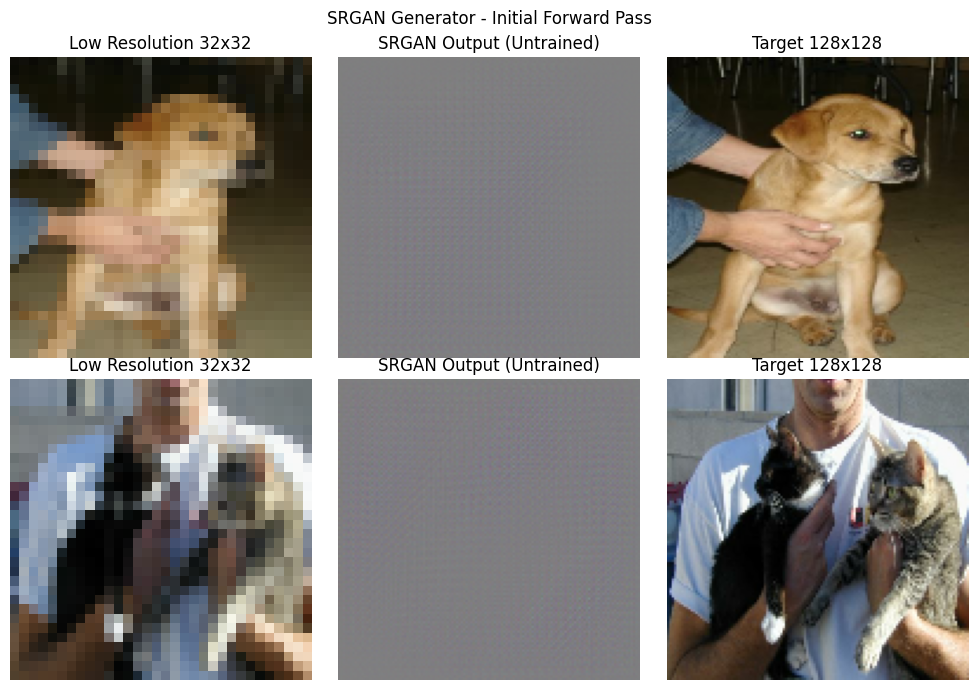


Generator forward pass completed successfully!


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# STEP 6.2: TEST SRGAN GENERATOR
# ==========================================

# Get one batch of real images without augmentation
hr_images, labels = next(iter(val_dataset))

# Convert 128x128 images to 32x32
lr_images = tf.image.resize(
    hr_images,
    [32, 32],
    method="area"
)

# Generate 128x128 images
generated_images = generator(
    lr_images[:2],
    training=False
)

print("===== GENERATOR FORWARD PASS TEST =====")

print("Low-resolution input shape:", lr_images[:2].shape)
print("Generated output shape:", generated_images.shape)
print("Target image shape:", hr_images[:2].shape)

print(
    "Generated pixel range:",
    float(tf.reduce_min(generated_images)),
    float(tf.reduce_max(generated_images))
)

# Check output
assert generated_images.shape == (2, 128, 128, 3)
assert np.all(np.isfinite(generated_images.numpy()))
assert float(tf.reduce_min(generated_images)) >= 0.0
assert float(tf.reduce_max(generated_images)) <= 1.0

# Show example images
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for i in range(2):
    axes[i, 0].imshow(lr_images[i].numpy())
    axes[i, 0].set_title("Low Resolution 32x32")

    axes[i, 1].imshow(generated_images[i].numpy())
    axes[i, 1].set_title("SRGAN Output (Untrained)")

    axes[i, 2].imshow(hr_images[i].numpy())
    axes[i, 2].set_title("Target 128x128")

    for j in range(3):
        axes[i, j].axis("off")

plt.suptitle("SRGAN Generator - Initial Forward Pass")
plt.tight_layout()
plt.show()

print("\nGenerator forward pass completed successfully!")


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# STEP 6.3: BUILD SRGAN DISCRIMINATOR
# ==========================================

tf.keras.utils.set_random_seed(42)

def discriminator_block(x, filters, strides=1, use_bn=True):

    x = layers.Conv2D(
        filters=filters,
        kernel_size=3,
        strides=strides,
        padding="same"
    )(x)

    if use_bn:
        x = layers.BatchNormalization()(x)

    x = layers.LeakyReLU(negative_slope=0.2)(x)

    return x


def build_discriminator():

    inputs = layers.Input(
        shape=(128, 128, 3)
    )

    # Initial feature extraction
    x = discriminator_block(
        inputs, 64, strides=1, use_bn=False
    )

    # Progressive downsampling
    x = discriminator_block(x, 64, strides=2)

    x = discriminator_block(x, 128, strides=1)
    x = discriminator_block(x, 128, strides=2)

    x = discriminator_block(x, 256, strides=1)
    x = discriminator_block(x, 256, strides=2)

    x = discriminator_block(x, 512, strides=1)
    x = discriminator_block(x, 512, strides=2)

    # Classification layers
    x = layers.Flatten()(x)

    x = layers.Dense(1024)(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    # Probability: real or generated
    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    discriminator = Model(
        inputs,
        outputs,
        name="SRGAN_Discriminator"
    )

    return discriminator


# Create discriminator
discriminator = build_discriminator()

# Display architecture
discriminator.summary()

print("\nSRGAN Discriminator created successfully!")
print("Input shape:", discriminator.input_shape)
print("Output shape:", discriminator.output_shape)
print("Total parameters:", discriminator.count_params())


Model: "SRGAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,80

 Total params: 38,249,281 (145.91 MB)

 Trainable params: 38,245,569 (145.90 MB)

 Non-trainable params: 3,712 (14.50 KB)


SRGAN Discriminator created successfully!
Input shape: (None, 128, 128, 3)
Output shape: (None, 1)
Total parameters: 38249281


In [ ]:

import tensorflow as tf
import numpy as np

# ==========================================
# STEP 6.4: TEST SRGAN DISCRIMINATOR
# ==========================================

# Use one validation image to minimize CPU workload
real_images = hr_images[:1]

# Generate one fake image
low_res_images = tf.image.resize(
    real_images,
    [32, 32],
    method="area"
)

fake_images = generator(
    low_res_images,
    training=False
)

# Discriminator predictions
real_predictions = discriminator(
    real_images,
    training=False
)

fake_predictions = discriminator(
    fake_images,
    training=False
)

print("===== DISCRIMINATOR FORWARD PASS TEST =====")

print("Real images shape:", real_images.shape)
print("Generated images shape:", fake_images.shape)

print("Real prediction shape:", real_predictions.shape)
print("Fake prediction shape:", fake_predictions.shape)

print(
    "Real image probability:",
    float(real_predictions[0, 0])
)

print(
    "Generated image probability:",
    float(fake_predictions[0, 0])
)

# Verify outputs
assert real_predictions.shape == (1, 1)
assert fake_predictions.shape == (1, 1)

assert np.all(np.isfinite(real_predictions.numpy()))
assert np.all(np.isfinite(fake_predictions.numpy()))

assert 0.0 <= float(real_predictions[0, 0]) <= 1.0
assert 0.0 <= float(fake_predictions[0, 0]) <= 1.0

print("\nDiscriminator forward pass completed successfully!")


===== DISCRIMINATOR FORWARD PASS TEST =====
Real images shape: (1, 128, 128, 3)
Generated images shape: (1, 128, 128, 3)
Real prediction shape: (1, 1)
Fake prediction shape: (1, 1)
Real image probability: 0.49835336208343506
Generated image probability: 0.4984135329723358

Discriminator forward pass completed successfully!


In [ ]:

import tensorflow as tf

# ==========================================
# STEP 7.1: CREATE SRGAN IMAGE PAIRS
# ==========================================

SRGAN_BATCH_SIZE = 8
LR_SIZE = 32
HR_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

def load_srgan_pair(path, label):

    # Read original image
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    # Normalize to [0, 1]
    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    # Create high-resolution target
    hr_image = tf.image.resize(
        image,
        [HR_SIZE, HR_SIZE],
        method="bicubic"
    )
    hr_image = tf.clip_by_value(
        hr_image, 0.0, 1.0
    )

    # Create low-resolution input
    lr_image = tf.image.resize(
        hr_image,
        [LR_SIZE, LR_SIZE],
        method="area"
    )

    lr_image = tf.clip_by_value(
        lr_image, 0.0, 1.0
    )

    return lr_image, hr_image


def create_srgan_dataset(dataframe, training=True):

    paths = dataframe["filepath"].astype(str).values
    labels = dataframe["label"].astype("float32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_srgan_pair,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(SRGAN_BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Create SRGAN training and validation datasets
srgan_train_dataset = create_srgan_dataset(
    model_train_df,
    training=True
)

srgan_val_dataset = create_srgan_dataset(
    val_df,
    training=False
)


# Test one batch
lr_batch, hr_batch = next(iter(srgan_train_dataset))

print("===== SRGAN DATASET VERIFICATION =====")

print("LR batch shape:", lr_batch.shape)
print("HR batch shape:", hr_batch.shape)

print(
    "LR pixel range:",
    float(tf.reduce_min(lr_batch)),
    float(tf.reduce_max(lr_batch))
)

print(
    "HR pixel range:",
    float(tf.reduce_min(hr_batch)),
    float(tf.reduce_max(hr_batch))
)

assert lr_batch.shape == (SRGAN_BATCH_SIZE, 32, 32, 3)
assert hr_batch.shape == (SRGAN_BATCH_SIZE, 128, 128, 3)

print("\nSRGAN paired-image dataset created successfully!")


===== SRGAN DATASET VERIFICATION =====
LR batch shape: (8, 32, 32, 3)
HR batch shape: (8, 128, 128, 3)
LR pixel range: 0.03484828770160675 1.0
HR pixel range: 0.0 1.0

SRGAN paired-image dataset created successfully!


In [ ]:

import tensorflow as tf
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input

# ==========================================
# STEP 7.2: SRGAN LOSS FUNCTIONS
# ==========================================

# 1. Load pretrained VGG19 for perceptual loss

vgg_base = VGG19(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

# Use intermediate feature representations
vgg_features = tf.keras.Model(
    inputs=vgg_base.input,
    outputs=vgg_base.get_layer(
        "block5_conv4"
    ).output,
    name="VGG19_Feature_Extractor"
)

# Freeze VGG19 weights
vgg_features.trainable = False


# 2. Pixel reconstruction loss (MSE)

def pixel_loss(real_hr, generated_hr):
    return tf.reduce_mean(
        tf.square(real_hr - generated_hr)
    )


# 3. Perceptual loss (VGG19 feature difference)

def perceptual_loss(real_hr, generated_hr):

    # Convert images from [0, 1] to [0, 255]
    real_input = preprocess_input(real_hr * 255.0)
    fake_input = preprocess_input(generated_hr * 255.0)

    real_features = vgg_features(
        real_input,
        training=False
    )

    fake_features = vgg_features(
        fake_input,
        training=False
    )

    return tf.reduce_mean(
        tf.square(real_features - fake_features)
    )


# 4. Adversarial loss

bce = tf.keras.losses.BinaryCrossentropy()

def generator_adversarial_loss(fake_predictions):
    return bce(
        tf.ones_like(fake_predictions),
        fake_predictions
    )


def discriminator_loss(real_predictions, fake_predictions):

    real_loss = bce(
        tf.ones_like(real_predictions),
        real_predictions
    )

    fake_loss = bce(
        tf.zeros_like(fake_predictions),
        fake_predictions
    )

    return real_loss + fake_loss


# 5. Verify VGG19 feature extractor

print("===== SRGAN LOSS SETUP =====")
print("VGG19 input shape:", vgg_features.input_shape)
print("VGG19 feature output:", vgg_features.output_shape)
print("VGG19 trainable:", vgg_features.trainable)
print("\nSRGAN loss functions created successfully!")


80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
===== SRGAN LOSS SETUP =====
VGG19 input shape: (None, 128, 128, 3)
VGG19 feature output: (None, 8, 8, 512)
VGG19 trainable: False

SRGAN loss functions created successfully!


In [ ]:

import tensorflow as tf
import numpy as np

# ==========================================
# STEP 7.3: VERIFY SRGAN LOSS FUNCTIONS
# ==========================================

# Use one pair of images
lr_sample = lr_batch[:1]
hr_sample = hr_batch[:1]

# Generate a super-resolution image
fake_hr = generator(lr_sample, training=False)

# Get discriminator predictions
real_pred = discriminator(hr_sample, training=False)
fake_pred = discriminator(fake_hr, training=False)

# Calculate each loss separately
loss_pixel = pixel_loss(hr_sample, fake_hr)

loss_perceptual = perceptual_loss(hr_sample, fake_hr)

loss_generator_adv = generator_adversarial_loss(fake_pred)

loss_discriminator = discriminator_loss(
    real_pred,
    fake_pred
)

# Display results
print("===== SRGAN LOSS VERIFICATION =====")

print("Pixel loss:", float(loss_pixel))
print("Perceptual loss:", float(loss_perceptual))
print("Generator adversarial loss:", float(loss_generator_adv))
print("Discriminator loss:", float(loss_discriminator))

# Check that all losses are valid
losses = [
    loss_pixel,
    loss_perceptual,
    loss_generator_adv,
    loss_discriminator
]

for loss in losses:
    assert np.isfinite(float(loss))
    assert float(loss) >= 0.0

print("\nAll SRGAN loss functions passed verification!")


===== SRGAN LOSS VERIFICATION =====
Pixel loss: 0.0995531678199768
Perceptual loss: 139.5003204345703
Generator adversarial loss: 0.6961033344268799
Discriminator loss: 1.3846673965454102

All SRGAN loss functions passed verification!


In [ ]:

import tensorflow as tf
import os

# ==========================================
# STEP 7.4: SRGAN TRAINING CONFIGURATION
# ==========================================

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Training parameters
SRGAN_EPOCHS = 150
SRGAN_BATCH_SIZE = 8
CHECKPOINT_INTERVAL = 5

# Loss weights
PIXEL_WEIGHT = 1.0
PERCEPTUAL_WEIGHT = 0.001
ADVERSARIAL_WEIGHT = 0.001

# Optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

# Combined generator loss
def total_generator_loss(
    real_hr,
    generated_hr,
    fake_predictions
):
    p_loss = pixel_loss(real_hr, generated_hr)

    perc_loss = perceptual_loss(
        real_hr,
        generated_hr
    )

    adv_loss = generator_adversarial_loss(
        fake_predictions
    )

    total_loss = (
        PIXEL_WEIGHT * p_loss
        + PERCEPTUAL_WEIGHT * perc_loss
        + ADVERSARIAL_WEIGHT * adv_loss
    )

    return total_loss, p_loss, perc_loss, adv_loss


# Create directories in Google Drive
project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

checkpoint_dir = os.path.join(
    project_dir,
    "SRGAN_Checkpoints"
)

figure_dir = os.path.join(
    project_dir,
    "SRGAN_Figures"
)

os.makedirs(checkpoint_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

print("===== SRGAN TRAINING CONFIGURATION =====")
print("Target epochs:", SRGAN_EPOCHS)
print("Batch size:", SRGAN_BATCH_SIZE)
print("Checkpoint interval:", CHECKPOINT_INTERVAL)

print("\nGenerator learning rate:",
      float(generator_optimizer.learning_rate.numpy()))

print("Discriminator learning rate:",
      float(discriminator_optimizer.learning_rate.numpy()))

print("\nLoss weights:")
print("Pixel:", PIXEL_WEIGHT)
print("Perceptual:", PERCEPTUAL_WEIGHT)
print("Adversarial:", ADVERSARIAL_WEIGHT)

print("\nCheckpoint directory:", checkpoint_dir)
print("Figure directory:", figure_dir)

print("\nSRGAN training configuration completed!")


===== SRGAN TRAINING CONFIGURATION =====
Target epochs: 150
Batch size: 8
Checkpoint interval: 5

Generator learning rate: 9.999999747378752e-05
Discriminator learning rate: 9.999999747378752e-05

Loss weights:
Pixel: 1.0
Perceptual: 0.001
Adversarial: 0.001

Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Checkpoints
Figure directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Figures

SRGAN training configuration completed!


In [ ]:

import os
import tensorflow as tf

# ==========================================
# STEP 7.5: SRGAN CHECKPOINT MANAGEMENT
# ==========================================

# Tracks the number of fully completed epochs
completed_epoch = tf.Variable(
    0,
    dtype=tf.int64,
    trainable=False,
    name="completed_epoch"
)

# Create checkpoint containing both networks,
# optimizer states, and training progress.
srgan_checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

# Keep the latest 5 checkpoints
checkpoint_manager = tf.train.CheckpointManager(
    srgan_checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

# Restore previous training if available
latest_checkpoint = checkpoint_manager.latest_checkpoint

if latest_checkpoint:
    restore_status = srgan_checkpoint.restore(
        latest_checkpoint
    )

    print("Previous checkpoint found!")
    print("Restored checkpoint:", latest_checkpoint)
    print("Completed epochs:", int(completed_epoch.numpy()))

else:
    print("No previous checkpoint found.")
    print("Training will begin from epoch 0.")

print("\n===== CHECKPOINT CONFIGURATION =====")
print("Checkpoint directory:", checkpoint_dir)
print("Checkpoints retained:", 5)
print("Save interval:", CHECKPOINT_INTERVAL, "epochs")
print("Current completed epoch:", int(completed_epoch.numpy()))

print("\nCheckpoint management configured successfully!")


No previous checkpoint found.
Training will begin from epoch 0.

===== CHECKPOINT CONFIGURATION =====
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Checkpoints
Checkpoints retained: 5
Save interval: 5 epochs
Current completed epoch: 0

Checkpoint management configured successfully!


In [ ]:

import tensorflow as tf

# ==========================================
# STEP 7.6: SRGAN TRAINING STEP
# ==========================================

@tf.function
def srgan_train_step(lr_images, hr_images):

    # Calculate generator and discriminator losses
    with tf.GradientTape(persistent=True) as tape:

        # Generate super-resolution images
        generated_hr = generator(
            lr_images,
            training=True
        )

        # Discriminator predictions
        real_predictions = discriminator(
            hr_images,
            training=True
        )

        fake_predictions = discriminator(
            generated_hr,
            training=True
        )

        # Generator losses
        (
            g_total,
            g_pixel,
            g_perceptual,
            g_adversarial
        ) = total_generator_loss(
            hr_images,
            generated_hr,
            fake_predictions
        )

        # Discriminator loss
        d_loss = discriminator_loss(
            real_predictions,
            fake_predictions
        )

    # Calculate gradients
    generator_gradients = tape.gradient(
        g_total,
        generator.trainable_variables
    )

    discriminator_gradients = tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    del tape

    # Update generator
    generator_optimizer.apply_gradients(
        zip(
            generator_gradients,
            generator.trainable_variables
        )
    )

    # Update discriminator
    discriminator_optimizer.apply_gradients(
        zip(
            discriminator_gradients,
            discriminator.trainable_variables
        )
    )

    return {
        "generator_loss": g_total,
        "pixel_loss": g_pixel,
        "perceptual_loss": g_perceptual,
        "adversarial_loss": g_adversarial,
        "discriminator_loss": d_loss
    }


print("===== SRGAN TRAINING FUNCTION =====")
print("Training function defined successfully!")
print("Generator and discriminator gradient updates configured.")
print("No training has started yet.")


===== SRGAN TRAINING FUNCTION =====
Training function defined successfully!
Generator and discriminator gradient updates configured.
No training has started yet.


In [ ]:

import tensorflow as tf
import numpy as np
import time

# ==========================================
# STEP 7.7: SINGLE SRGAN TRAINING STEP TEST
# ==========================================

print("===== SRGAN TRAINING STEP TEST =====")

# Use one low-resolution / high-resolution pair
test_lr = lr_batch[:1]
test_hr = hr_batch[:1]

print("LR input:", test_lr.shape)
print("HR target:", test_hr.shape)

# Time one training update
start_time = time.time()

try:
    losses = srgan_train_step(test_lr, test_hr)

    elapsed = time.time() - start_time

    print("\nTraining step completed!")

    for name, value in losses.items():
        loss_value = float(value.numpy())
        print(f"{name}: {loss_value:.6f}")

        assert np.isfinite(loss_value), (
            f"Invalid loss detected: {name}"
        )

    print(f"\nElapsed time: {elapsed:.2f} seconds")
    print("All gradients and losses computed successfully!")

except Exception as error:
    print("\nTraining step failed:")
    print(type(error).__name__, str(error))
    raise


===== SRGAN TRAINING STEP TEST =====
LR input: (1, 32, 32, 3)
HR target: (1, 128, 128, 3)

Training step completed!
generator_loss: 0.245791
pixel_loss: 0.103273
perceptual_loss: 141.654602
adversarial_loss: 0.863391
discriminator_loss: 1.440535

Elapsed time: 21.22 seconds
All gradients and losses computed successfully!


In [ ]:

import os

# ==========================================
# STEP 7.8: VERIFY SAVED PROJECT FILES
# ==========================================

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

required_files = [
    "train_split.csv",
    "test_split.csv",
    "model_train_split.csv",
    "validation_split.csv",
    "dataset_verification.pkl"
]

print("===== PROJECT FILE VERIFICATION =====")

all_found = True

for filename in required_files:
    path = os.path.join(project_dir, filename)
    exists = os.path.isfile(path)

    print(f"{filename}: {'FOUND' if exists else 'MISSING'}")

    if not exists:
        all_found = False

print("\nCheckpoint directory exists:",
      os.path.isdir(checkpoint_dir))

print("Figure directory exists:",
      os.path.isdir(figure_dir))

if all_found:
    print("\nAll required dataset files are saved!")
else:
    print("\nSome files are missing. Review before continuing.")


===== PROJECT FILE VERIFICATION =====
train_split.csv: FOUND
test_split.csv: FOUND
model_train_split.csv: FOUND
validation_split.csv: FOUND
dataset_verification.pkl: FOUND

Checkpoint directory exists: True
Figure directory exists: True

All required dataset files are saved!


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# STEP 7.9: MEMORY-EFFICIENT DISCRIMINATOR
# ==========================================

def build_efficient_discriminator():

    inputs = layers.Input(shape=(128, 128, 3))

    x = discriminator_block(
        inputs, 64, strides=1, use_bn=False
    )

    x = discriminator_block(x, 64, strides=2)
    x = discriminator_block(x, 128, strides=1)
    x = discriminator_block(x, 128, strides=2)
    x = discriminator_block(x, 256, strides=1)
    x = discriminator_block(x, 256, strides=2)
    x = discriminator_block(x, 512, strides=1)
    x = discriminator_block(x, 512, strides=2)

    # Replace Flatten with global average pooling
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(1024)(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return Model(
        inputs,
        outputs,
        name="SRGAN_Efficient_Discriminator"
    )


# Replace the untrained discriminator.
# We will rebuild the optimizer and checkpoint objects
# before official training.
discriminator = build_efficient_discriminator()

discriminator.summary()

print("\n===== EFFICIENT DISCRIMINATOR =====")
print("Input shape:", discriminator.input_shape)
print("Output shape:", discriminator.output_shape)
print("Total parameters:", discriminator.count_params())

assert discriminator.input_shape == (None, 128, 128, 3)
assert discriminator.output_shape == (None, 1)

print("\nEfficient discriminator created successfully!")


Model: "SRGAN_Efficient_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,80

 Total params: 5,219,137 (19.91 MB)

 Trainable params: 5,215,425 (19.90 MB)

 Non-trainable params: 3,712 (14.50 KB)


===== EFFICIENT DISCRIMINATOR =====
Input shape: (None, 128, 128, 3)
Output shape: (None, 1)
Total parameters: 5219137

Efficient discriminator created successfully!


In [ ]:

import tensorflow as tf
import os

# ==========================================
# STEP 7.10: CLEAN SRGAN INITIALIZATION
# ==========================================

# This cell is for initial setup only.
# Do not rerun it after actual training begins,
# unless restoring from a saved checkpoint.

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Rebuild the generator from its original architecture
generator = build_generator(num_residual_blocks=8)

# Rebuild the memory-efficient discriminator
discriminator = build_efficient_discriminator()

# Fresh optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

# Track completed epochs
completed_epoch = tf.Variable(
    0,
    dtype=tf.int64,
    trainable=False,
    name="completed_epoch"
)

# Rebuild checkpoint object with the correct models
srgan_checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    srgan_checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

# Restore training if a checkpoint exists
if checkpoint_manager.latest_checkpoint:
    srgan_checkpoint.restore(
        checkpoint_manager.latest_checkpoint
    )
    print("Checkpoint restored:", checkpoint_manager.latest_checkpoint)
else:
    print("Fresh SRGAN models initialized.")

print("\n===== CLEAN TRAINING SETUP =====")
print("Generator parameters:", generator.count_params())
print("Discriminator parameters:", discriminator.count_params())
print("Completed epochs:", int(completed_epoch.numpy()))
print("Checkpoint directory:", checkpoint_dir)

print("\nSRGAN initialization completed successfully!")


Fresh SRGAN models initialized.

===== CLEAN TRAINING SETUP =====
Generator parameters: 959427
Discriminator parameters: 5219137
Completed epochs: 0
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Checkpoints

SRGAN initialization completed successfully!


In [ ]:

import tensorflow as tf

# ==========================================
# STEP 7.11: FINAL SRGAN TRAINING FUNCTION
# ==========================================

@tf.function
def srgan_train_step(lr_images, hr_images):

    with tf.GradientTape(persistent=True) as tape:

        # Generate high-resolution images
        generated_hr = generator(
            lr_images,
            training=True
        )

        # Discriminator predictions
        real_predictions = discriminator(
            hr_images,
            training=True
        )

        fake_predictions = discriminator(
            generated_hr,
            training=True
        )

        # Generator losses
        (
            g_total,
            g_pixel,
            g_perceptual,
            g_adversarial
        ) = total_generator_loss(
            hr_images,
            generated_hr,
            fake_predictions
        )

        # Discriminator loss
        d_loss = discriminator_loss(
            real_predictions,
            fake_predictions
        )

    # Compute gradients
    g_gradients = tape.gradient(
        g_total,
        generator.trainable_variables
    )

    d_gradients = tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    del tape

    # Update generator and discriminator
    generator_optimizer.apply_gradients(
        zip(
            g_gradients,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            d_gradients,
            discriminator.trainable_variables
        )
    )

    return {
        "generator_loss": g_total,
        "pixel_loss": g_pixel,
        "perceptual_loss": g_perceptual,
        "adversarial_loss": g_adversarial,
        "discriminator_loss": d_loss
    }


# Verify training configuration without updating weights
print("===== FINAL SRGAN TRAINING FUNCTION =====")

print("Generator:", generator.name)
print("Generator parameters:", generator.count_params())

print("Discriminator:", discriminator.name)
print("Discriminator parameters:", discriminator.count_params())

print("Completed epochs:", int(completed_epoch.numpy()))

assert int(completed_epoch.numpy()) == 0
assert generator.count_params() == 959427
assert discriminator.count_params() == 5219137

print("\nTraining function redefined successfully!")
print("No model weights were updated in this step.")


===== FINAL SRGAN TRAINING FUNCTION =====
Generator: SRGAN_Generator
Generator parameters: 959427
Discriminator: SRGAN_Efficient_Discriminator
Discriminator parameters: 5219137
Completed epochs: 0

Training function redefined successfully!
No model weights were updated in this step.


In [ ]:

import tensorflow as tf

# ==========================================
# STEP 7.12: SRGAN VALIDATION FUNCTION
# ==========================================

@tf.function
def srgan_validation_step(lr_images, hr_images):

    # Generate images without updating weights
    generated_hr = generator(
        lr_images,
        training=False
    )

    generated_hr = tf.clip_by_value(
        generated_hr, 0.0, 1.0
    )

    # Compute PSNR for each image
    psnr_values = tf.image.psnr(
        hr_images,
        generated_hr,
        max_val=1.0
    )

    # Compute SSIM for each image
    ssim_values = tf.image.ssim(
        hr_images,
        generated_hr,
        max_val=1.0
    )

    return psnr_values, ssim_values


def evaluate_srgan(dataset):

    psnr_metric = tf.keras.metrics.Mean()
    ssim_metric = tf.keras.metrics.Mean()

    for lr_images, hr_images in dataset:

        psnr_values, ssim_values = srgan_validation_step(
            lr_images,
            hr_images
        )

        psnr_metric.update_state(psnr_values)
        ssim_metric.update_state(ssim_values)

    return {
        "val_psnr": float(psnr_metric.result().numpy()),
        "val_ssim": float(ssim_metric.result().numpy())
    }


print("===== SRGAN VALIDATION SETUP =====")
print("Metrics: PSNR and SSIM")
print("Validation images:", len(val_df))
print("Validation function created successfully!")
print("No training or validation inference has started.")


===== SRGAN VALIDATION SETUP =====
Metrics: PSNR and SSIM
Validation images: 1746
Validation function created successfully!
No training or validation inference has started.


In [ ]:

import os
import time
import pandas as pd
import numpy as np
import tensorflow as tf

# ==========================================
# STEP 7.13: SRGAN EPOCH TRAINING LOOP
# ==========================================

history_file = os.path.join(
    project_dir,
    "srgan_training_history.csv"
)

history_columns = [
    "epoch",
    "generator_loss",
    "pixel_loss",
    "perceptual_loss",
    "adversarial_loss",
    "discriminator_loss",
    "val_psnr",
    "val_ssim",
    "epoch_seconds"
]


def train_srgan(
    train_data,
    val_data,
    target_epochs=150
):

    start_epoch = int(completed_epoch.numpy())

    print("===== SRGAN TRAINING =====")
    print(f"Resuming from epoch: {start_epoch}")
    print(f"Target epochs: {target_epochs}")

    if start_epoch >= target_epochs:
        print("Training target already reached.")
        return

    for epoch in range(start_epoch, target_epochs):

        start_time = time.time()

        # Track training losses
        metrics = {
            "generator_loss": tf.keras.metrics.Mean(),
            "pixel_loss": tf.keras.metrics.Mean(),
            "perceptual_loss": tf.keras.metrics.Mean(),
            "adversarial_loss": tf.keras.metrics.Mean(),
            "discriminator_loss": tf.keras.metrics.Mean()
        }

        # One full training epoch
        for lr_images, hr_images in train_data:

            losses = srgan_train_step(
                lr_images,
                hr_images
            )

            batch_size = int(tf.shape(lr_images)[0])

            for name, value in losses.items():
                metrics[name].update_state(
                    value,
                    sample_weight=batch_size
                )

        # Evaluate generator on validation images
        validation_results = evaluate_srgan(val_data)

        epoch_seconds = time.time() - start_time

        # Collect results
        row = {
            "epoch": epoch + 1,
            **{
                name: float(metric.result().numpy())
                for name, metric in metrics.items()
            },
            **validation_results,
            "epoch_seconds": epoch_seconds
        }

        # Save epoch history to Google Drive
        if os.path.exists(history_file):
            history_df = pd.read_csv(history_file)
        else:
            history_df = pd.DataFrame(
                columns=history_columns
            )

        history_df = history_df[
            history_df["epoch"] != epoch + 1
        ]

        history_df = pd.concat(
            [history_df, pd.DataFrame([row])],
            ignore_index=True
        )

        history_df = history_df.sort_values("epoch")
        history_df.to_csv(history_file, index=False)

        # Mark completed epoch
        completed_epoch.assign(epoch + 1)

        # Save checkpoint periodically
        if (
            (epoch + 1) % CHECKPOINT_INTERVAL == 0
            or (epoch + 1) == target_epochs
        ):
            checkpoint_path = checkpoint_manager.save(
                checkpoint_number=epoch + 1
            )
            print("Checkpoint saved:", checkpoint_path)

        print(
            f"Epoch {epoch + 1}/{target_epochs} | "
            f"G Loss: {row['generator_loss']:.4f} | "
            f"D Loss: {row['discriminator_loss']:.4f} | "
            f"PSNR: {row['val_psnr']:.2f} | "
            f"SSIM: {row['val_ssim']:.4f} | "
            f"Time: {epoch_seconds:.1f}s"
        )

    print("\nSRGAN training completed!")


print("===== TRAINING LOOP CONFIGURATION =====")
print("Target epochs:", SRGAN_EPOCHS)
print("Checkpoint interval:", CHECKPOINT_INTERVAL)
print("History file:", history_file)
print("Current completed epoch:", int(completed_epoch.numpy()))
print("\nTraining loop defined successfully.")
print("Training has NOT started.")


===== TRAINING LOOP CONFIGURATION =====
Target epochs: 150
Checkpoint interval: 5
History file: /content/drive/MyDrive/Applied_AI_Midterm/srgan_training_history.csv
Current completed epoch: 0

Training loop defined successfully.
Training has NOT started.


In [ ]:

import os
import pandas as pd

# ==========================================
# STEP 7.14: CHECKPOINT HISTORY RECOVERY
# ==========================================

def synchronize_training_history():

    restored_epoch = int(completed_epoch.numpy())

    print("===== TRAINING RECOVERY CHECK =====")
    print("Last checkpoint epoch:", restored_epoch)

    if not os.path.exists(history_file):
        print("No previous training history found.")
        print("Training will begin from epoch:",
              restored_epoch)
        return

    history_df = pd.read_csv(history_file)

    if history_df.empty:
        print("Training history is empty.")
        return

    # Keep records only up to the restored epoch
    history_df = history_df[
        history_df["epoch"] <= restored_epoch
    ].copy()

    # Remove repeated epoch records
    history_df = history_df.drop_duplicates(
        subset=["epoch"],
        keep="last"
    )

    history_df = history_df.sort_values("epoch")
    history_df.to_csv(history_file, index=False)

    print("History synchronized successfully.")
    print("Saved history rows:", len(history_df))
    print("Next epoch:", restored_epoch + 1)


# Run synchronization before official training
synchronize_training_history()

print("\nRecovery verification completed!")


===== TRAINING RECOVERY CHECK =====
Last checkpoint epoch: 0
No previous training history found.
Training will begin from epoch: 0

Recovery verification completed!


In [ ]:
import tensorflow as tf

print("===== GPU AVAILABILITY CHECK =====")
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU available:", gpus)
    print("Ready for GPU training.")
else:
    print("No GPU detected in the current runtime.")
    print("Currently using CPU.")

print("\nSaved project files will remain in Google Drive.")

===== GPU AVAILABILITY CHECK =====
TensorFlow version: 2.21.0
No GPU detected in the current runtime.
Currently using CPU.

Saved project files will remain in Google Drive.


In [ ]:

import os
import tensorflow as tf

# ==========================================
# STEP 8.3: MODEL A TRAINING CONFIGURATION
# ==========================================

# Project directory
project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

# Model A checkpoint directory
model_a_dir = os.path.join(
    project_dir,
    "Model_A_Checkpoints"
)

os.makedirs(model_a_dir, exist_ok=True)

# Training parameters
MODEL_A_INITIAL_EPOCHS = 5
MODEL_A_BATCH_SIZE = 32
MODEL_A_LEARNING_RATE = 1e-3

# Compile Model A
model_A.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=MODEL_A_LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Save the best model based on validation loss
best_model_path = os.path.join(
    model_a_dir,
    "model_A_best.keras"
)

best_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=best_model_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    mode="min",
    verbose=1
)

# Save a complete model after every epoch
epoch_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        model_a_dir,
        "model_A_epoch_{epoch:02d}.keras"
    ),
    save_weights_only=False,
    save_freq="epoch",
    verbose=1
)

# Record training metrics
csv_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(model_a_dir, "training_log.csv"),
    append=True
)

# Callback collection
model_a_callbacks = [
    best_checkpoint,
    epoch_checkpoint,
    csv_logger
]

print("===== MODEL A TRAINING CONFIGURATION =====")

print("Model:", model_A.name)
print("Initial epochs:", MODEL_A_INITIAL_EPOCHS)
print("Batch size:", MODEL_A_BATCH_SIZE)
print("Learning rate:", MODEL_A_LEARNING_RATE)

print("\nCheckpoint directory:", model_a_dir)
print("Best model:", best_model_path)
print("Checkpoints saved: Every epoch")

print("\nMetrics: Accuracy and AUC")
print("Training configuration completed successfully!")
print("Training has NOT started.")


===== MODEL A TRAINING CONFIGURATION =====
Model: Model_A_MobileNetV2
Initial epochs: 5
Batch size: 32
Learning rate: 0.001

Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints
Best model: /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/model_A_best.keras
Checkpoints saved: Every epoch

Metrics: Accuracy and AUC
Training configuration completed successfully!
Training has NOT started.


In [ ]:

import os
import tensorflow as tf

# ==========================================
# STEP 8.4: MODEL A FINE-TUNING SETUP
# ==========================================

MODEL_A_FINETUNE_EPOCHS = 3
MODEL_A_FINETUNE_LR = 1e-5
LAYERS_TO_UNFREEZE = 30

# Separate directory for fine-tuning checkpoints
model_a_finetune_dir = os.path.join(
    model_a_dir,
    "Fine_Tuning"
)

os.makedirs(model_a_finetune_dir, exist_ok=True)


def prepare_model_a_finetuning(model, base_model):

    # Unfreeze the pretrained network
    base_model.trainable = True

    # Keep all except the final 30 layers frozen
    for layer in base_model.layers[:-LAYERS_TO_UNFREEZE]:
        layer.trainable = False

    # Keep BatchNormalization layers frozen
    # for more stable fine-tuning
    for layer in base_model.layers:
        if isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        ):
            layer.trainable = False

    # Recompile with a smaller learning rate
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=MODEL_A_FINETUNE_LR
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),
            tf.keras.metrics.AUC(
                name="auc"
            )
        ]
    )

    return model


def get_model_a_finetune_callbacks():

    best_finetuned = tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            model_a_finetune_dir,
            "model_A_finetuned_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    )

    epoch_finetuned = tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            model_a_finetune_dir,
            "model_A_finetuned_epoch_{epoch:02d}.keras"
        ),
        save_freq="epoch",
        verbose=1
    )

    finetune_logger = tf.keras.callbacks.CSVLogger(
        os.path.join(
            model_a_finetune_dir,
            "finetuning_log.csv"
        ),
        append=True
    )

    return [
        best_finetuned,
        epoch_finetuned,
        finetune_logger
    ]


print("===== MODEL A FINE-TUNING CONFIGURATION =====")
print("Fine-tuning epochs:", MODEL_A_FINETUNE_EPOCHS)
print("Learning rate:", MODEL_A_FINETUNE_LR)
print("Final layers to unfreeze:", LAYERS_TO_UNFREEZE)
print("Checkpoint directory:", model_a_finetune_dir)

print("\nFine-tuning functions created successfully!")
print("Fine-tuning has NOT started.")
print("Model A's pretrained layers remain frozen.")


===== MODEL A FINE-TUNING CONFIGURATION =====
Fine-tuning epochs: 3
Learning rate: 1e-05
Final layers to unfreeze: 30
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/Fine_Tuning

Fine-tuning functions created successfully!
Fine-tuning has NOT started.
Model A's pretrained layers remain frozen.


In [ ]:

import os
import re
import tensorflow as tf

# ==========================================
# STEP 8.5: MODEL A TRAINING / RESUME SETUP
# ==========================================

def find_latest_model_a_checkpoint(directory):

    checkpoint_files = []

    for filename in os.listdir(directory):

        match = re.fullmatch(
            r"model_A_epoch_(\d+)\.keras",
            filename
        )

        if match:
            epoch_number = int(match.group(1))

            checkpoint_files.append(
                (epoch_number, os.path.join(directory, filename))
            )

    if not checkpoint_files:
        return 0, None

    return max(checkpoint_files, key=lambda item: item[0])


def train_or_resume_model_a():

    global model_A

    completed, checkpoint_path = (
        find_latest_model_a_checkpoint(model_a_dir)
    )

    if checkpoint_path is not None:

        print("Restoring checkpoint:", checkpoint_path)

        # The saved model includes optimizer state
        model_A = tf.keras.models.load_model(
            checkpoint_path
        )

    else:
        print("No previous Model A checkpoint found.")
        print("Using newly initialized Model A.")

    if completed >= MODEL_A_INITIAL_EPOCHS:
        print("Initial training is already complete.")
        return model_A

    print(
        f"Training Model A from epoch "
        f"{completed + 1} to {MODEL_A_INITIAL_EPOCHS}"
    )

    history = model_A.fit(
        train_dataset,
        validation_data=val_dataset,
        initial_epoch=completed,
        epochs=MODEL_A_INITIAL_EPOCHS,
        callbacks=model_a_callbacks,
        verbose=1
    )

    print("\nModel A initial training completed!")

    return model_A


print("===== MODEL A TRAINING / RESUME SETUP =====")

completed, latest_path = find_latest_model_a_checkpoint(
    model_a_dir
)

print("Saved epochs:", completed)
print("Latest checkpoint:", latest_path)
print("Target initial epochs:", MODEL_A_INITIAL_EPOCHS)

print("\nTraining/resume function created successfully.")
print("Training has NOT started.")


===== MODEL A TRAINING / RESUME SETUP =====
Saved epochs: 0
Latest checkpoint: None
Target initial epochs: 5

Training/resume function created successfully.
Training has NOT started.


In [ ]:

import os
import re
import tensorflow as tf

# ==========================================
# STEP 8.6: MODEL A FINE-TUNING / RESUME
# ==========================================

def find_latest_finetune_checkpoint(directory):

    checkpoints = []

    for filename in os.listdir(directory):

        match = re.fullmatch(
            r"model_A_finetuned_epoch_(\d+)\.keras",
            filename
        )

        if match:
            epoch_num = int(match.group(1))

            checkpoints.append(
                (epoch_num, os.path.join(directory, filename))
            )

    if not checkpoints:
        return 0, None

    return max(checkpoints, key=lambda item: item[0])


def finetune_or_resume_model_a():

    global model_A

    # Ensure initial training has completed
    initial_completed, initial_path = (
        find_latest_model_a_checkpoint(model_a_dir)
    )

    if initial_completed < MODEL_A_INITIAL_EPOCHS:
        raise RuntimeError(
            "Complete Model A's initial 5 epochs before fine-tuning."
        )

    # Check for existing fine-tuning checkpoints
    completed, checkpoint_path = (
        find_latest_finetune_checkpoint(model_a_finetune_dir)
    )

    if checkpoint_path is not None:

        print("Restoring fine-tuning:", checkpoint_path)

        model_A = tf.keras.models.load_model(
            checkpoint_path
        )

    else:
        print("Preparing Model A for fine-tuning.")

        # Load the fully trained initial-stage model
        model_A = tf.keras.models.load_model(initial_path)

        # Recover the nested MobileNetV2 base
        base_model = next(
            layer for layer in model_A.layers
            if isinstance(layer, tf.keras.Model)
            and "mobilenetv2" in layer.name.lower()
        )

        model_A = prepare_model_a_finetuning(
            model_A,
            base_model
        )

    if completed >= MODEL_A_FINETUNE_EPOCHS:
        print("Fine-tuning is already complete.")
        return model_A

    # Start at 0 or resume after completed epochs
    model_A.fit(
        train_dataset,
        validation_data=val_dataset,
        initial_epoch=completed,
        epochs=MODEL_A_FINETUNE_EPOCHS,
        callbacks=get_model_a_finetune_callbacks(),
        verbose=1
    )

    print("\nModel A fine-tuning completed!")

    return model_A


print("===== MODEL A FINE-TUNING RECOVERY =====")

completed, latest_path = find_latest_finetune_checkpoint(
    model_a_finetune_dir
)

print("Saved fine-tuning epochs:", completed)
print("Latest fine-tuning checkpoint:", latest_path)
print("Target fine-tuning epochs:", MODEL_A_FINETUNE_EPOCHS)

print("\nFine-tuning recovery function created successfully.")
print("Fine-tuning has NOT started.")


===== MODEL A FINE-TUNING RECOVERY =====
Saved fine-tuning epochs: 0
Latest fine-tuning checkpoint: None
Target fine-tuning epochs: 3

Fine-tuning recovery function created successfully.
Fine-tuning has NOT started.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

# ==========================================
# STEP 8.7: CLASSIFICATION EVALUATION
# ==========================================

def evaluate_classifier(model, dataset, model_name):

    # Collect predicted probabilities and labels
    y_true = []
    y_prob = []

    for images, labels in dataset:

        probabilities = model(
            images,
            training=False
        ).numpy().reshape(-1)

        y_true.extend(labels.numpy().astype(int))
        y_prob.extend(probabilities)

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)

    # Convert probabilities into binary classes
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculate evaluation metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "AUC": roc_auc_score(y_true, y_prob)
    }

    # Display metrics
    print(f"\n===== {model_name} EVALUATION =====")

    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Cat", "Dog"]
    )

    display.plot(cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)

    plt.figure(figsize=(6, 5))
    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {results['AUC']:.4f}"
    )
    plt.plot([0, 1], [0, 1], "--", color="gray")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} - ROC Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return results


print("===== CLASSIFICATION EVALUATION SETUP =====")
print("Metrics: Accuracy, Precision, Recall, F1, AUC")
print("Additional plots: Confusion Matrix and ROC Curve")
print("Held-out test images:", len(test_df))

print("\nEvaluation function created successfully!")
print("No model evaluation has started.")


===== CLASSIFICATION EVALUATION SETUP =====
Metrics: Accuracy, Precision, Recall, F1, AUC
Additional plots: Confusion Matrix and ROC Curve
Held-out test images: 7479

Evaluation function created successfully!
No model evaluation has started.


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# STEP 8.8: BUILD MODEL B - MOBILENETV2
# ==========================================

tf.keras.utils.set_random_seed(123)

# Load a separate pretrained MobileNetV2
base_model_B = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model_B.trainable = False

# Input images will eventually come from SRGAN
inputs_B = layers.Input(shape=(128, 128, 3))

# Convert [0, 1] to [-1, 1] for MobileNetV2
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(inputs_B)

# Extract image features
x = base_model_B(x, training=False)

# Binary classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs_B = layers.Dense(
    1,
    activation="sigmoid"
)(x)

# Create Model B
model_B = Model(
    inputs=inputs_B,
    outputs=outputs_B,
    name="Model_B_MobileNetV2"
)

# Compile Model B
model_B.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Verify architecture
print("===== MODEL B ARCHITECTURE =====")
print("Model:", model_B.name)
print("Input shape:", model_B.input_shape)
print("Output shape:", model_B.output_shape)
print("Total parameters:", model_B.count_params())
print("Trainable parameters:",
      sum(
          tf.keras.backend.count_params(w)
          for w in model_B.trainable_weights
      ))

assert model_B.input_shape == (None, 128, 128, 3)
assert model_B.output_shape == (None, 1)

print("\nModel B created successfully!")
print("No training has started.")


===== MODEL B ARCHITECTURE =====
Model: Model_B_MobileNetV2
Input shape: (None, 128, 128, 3)
Output shape: (None, 1)
Total parameters: 2259265
Trainable parameters: 1281

Model B created successfully!
No training has started.


In [ ]:

import tensorflow as tf

# ==========================================
# STEP 8.9: MODEL B IMAGE PIPELINE
# ==========================================

def create_model_b_dataset(
    srgan_dataset,
    trained_generator
):
    """
    Convert paired SRGAN data into
    (enhanced_image, classification_label).

    The input dataset must contain:
        (LR image, HR image, class label)
    """

    def enhance_images(lr_images, hr_images, labels):

        # Generate 128x128 images using SRGAN
        enhanced_images = trained_generator(
            lr_images,
            training=False
        )

        enhanced_images = tf.clip_by_value(
            enhanced_images,
            0.0,
            1.0
        )

        return enhanced_images, labels

    return srgan_dataset.map(
        enhance_images,
        num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)


print("===== MODEL B DATA PIPELINE =====")
print("Expected generator input: 32x32x3")
print("Expected Model B input: 128x128x3")
print("Class labels: Cat=0, Dog=1")

print("\nModel B image pipeline function created successfully!")
print("No images have been generated.")


===== MODEL B DATA PIPELINE =====
Expected generator input: 32x32x3
Expected Model B input: 128x128x3
Class labels: Cat=0, Dog=1

Model B image pipeline function created successfully!
No images have been generated.


In [ ]:

import tensorflow as tf
import numpy as np

# ==========================================
# STEP 8.10: LABELED DATASET FOR MODEL B
# ==========================================

def load_labeled_srgan_pair(path, label):

    # Read and decode original image
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Normalize original image to [0, 1]
    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    # High-resolution reference: 128x128
    hr_image = tf.image.resize(
        image,
        [128, 128],
        method="bicubic"
    )

    hr_image = tf.clip_by_value(
        hr_image, 0.0, 1.0
    )

    # Low-resolution input: 32x32
    lr_image = tf.image.resize(
        hr_image,
        [32, 32],
        method="area"
    )

    lr_image = tf.clip_by_value(
        lr_image, 0.0, 1.0
    )

    return (
        lr_image,
        hr_image,
        tf.cast(label, tf.float32)
    )


def create_labeled_srgan_dataset(
    dataframe,
    training=False
):

    paths = dataframe["filepath"].astype(str).values
    labels = dataframe["label"].astype("float32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_labeled_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(8)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


# Create separate datasets for Model B
model_b_train_pairs = create_labeled_srgan_dataset(
    model_train_df,
    training=True
)

model_b_val_pairs = create_labeled_srgan_dataset(
    val_df,
    training=False
)

model_b_test_pairs = create_labeled_srgan_dataset(
    test_df,
    training=False
)


# Verify one batch WITHOUT running the generator
lr_images, hr_images, labels = next(
    iter(model_b_train_pairs)
)

print("===== MODEL B LABELED DATASET =====")

print("LR images:", lr_images.shape)
print("HR images:", hr_images.shape)
print("Labels:", labels.shape)

print("Sample labels:", labels.numpy())

print(
    "LR pixel range:",
    float(tf.reduce_min(lr_images)),
    float(tf.reduce_max(lr_images))
)

assert lr_images.shape == (8, 32, 32, 3)
assert hr_images.shape == (8, 128, 128, 3)
assert labels.shape == (8,)

assert np.all(
    np.isin(labels.numpy(), [0.0, 1.0])
)

print("\nLabeled SRGAN datasets created successfully!")
print("No SRGAN enhancement or model training occurred.")


===== MODEL B LABELED DATASET =====
LR images: (8, 32, 32, 3)
HR images: (8, 128, 128, 3)
Labels: (8,)
Sample labels: [0. 0. 0. 0. 0. 1. 1. 1.]
LR pixel range: 0.0 1.0

Labeled SRGAN datasets created successfully!
No SRGAN enhancement or model training occurred.


In [ ]:

import os
import tensorflow as tf

# ==========================================
# STEP 8.11: MODEL B TRAINING CONFIGURATION
# ==========================================

MODEL_B_INITIAL_EPOCHS = 5
MODEL_B_FINETUNE_EPOCHS = 3
MODEL_B_BATCH_SIZE = 8

MODEL_B_LEARNING_RATE = 1e-3
MODEL_B_FINETUNE_LR = 1e-5

# Separate checkpoint directory
model_b_dir = os.path.join(
    project_dir,
    "Model_B_Checkpoints"
)

os.makedirs(model_b_dir, exist_ok=True)

# Compile Model B
model_B.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=MODEL_B_LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Best validation checkpoint
model_b_best_path = os.path.join(
    model_b_dir,
    "model_B_best.keras"
)

model_b_best_checkpoint = (
    tf.keras.callbacks.ModelCheckpoint(
        filepath=model_b_best_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
)

# Save each completed epoch
model_b_epoch_checkpoint = (
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            model_b_dir,
            "model_B_epoch_{epoch:02d}.keras"
        ),
        save_freq="epoch",
        verbose=1
    )
)

# Training history
model_b_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(
        model_b_dir,
        "training_log.csv"
    ),
    append=True
)

model_b_callbacks = [
    model_b_best_checkpoint,
    model_b_epoch_checkpoint,
    model_b_logger
]

print("===== MODEL B TRAINING CONFIGURATION =====")
print("Model:", model_B.name)
print("Initial epochs:", MODEL_B_INITIAL_EPOCHS)
print("Fine-tuning epochs:", MODEL_B_FINETUNE_EPOCHS)
print("Batch size:", MODEL_B_BATCH_SIZE)
print("Initial learning rate:", MODEL_B_LEARNING_RATE)
print("Fine-tuning learning rate:", MODEL_B_FINETUNE_LR)

print("\nCheckpoint directory:", model_b_dir)
print("Best model path:", model_b_best_path)

print("\nModel B training configuration completed!")
print("Training has NOT started.")


===== MODEL B TRAINING CONFIGURATION =====
Model: Model_B_MobileNetV2
Initial epochs: 5
Fine-tuning epochs: 3
Batch size: 8
Initial learning rate: 0.001
Fine-tuning learning rate: 1e-05

Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/Model_B_Checkpoints
Best model path: /content/drive/MyDrive/Applied_AI_Midterm/Model_B_Checkpoints/model_B_best.keras

Model B training configuration completed!
Training has NOT started.


In [ ]:

import os
import re
import tensorflow as tf

# ==========================================
# STEP 8.12: MODEL B FINE-TUNING AND RECOVERY
# ==========================================

# Separate fine-tuning checkpoint directory
model_b_finetune_dir = os.path.join(
    model_b_dir,
    "Fine_Tuning"
)

os.makedirs(model_b_finetune_dir, exist_ok=True)


# ------------------------------------------
# 1. Prepare fine-tuning
# ------------------------------------------

def prepare_model_b_finetuning(model):

    # Find the pretrained MobileNetV2 base
    base_model = next(
        layer for layer in model.layers
        if isinstance(layer, tf.keras.Model)
        and "mobilenetv2" in layer.name.lower()
    )

    # Unfreeze MobileNetV2
    base_model.trainable = True

    # Freeze all except the last 30 layers
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    # Keep BatchNormalization layers frozen
    for layer in base_model.layers:
        if isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        ):
            layer.trainable = False

    # Compile with lower learning rate
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=MODEL_B_FINETUNE_LR
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),
            tf.keras.metrics.AUC(
                name="auc"
            )
        ]
    )

    return model


# ------------------------------------------
# 2. Configure fine-tuning checkpoints
# ------------------------------------------

def get_model_b_finetune_callbacks():

    best_checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            model_b_finetune_dir,
            "model_B_finetuned_best.keras"
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )

    epoch_checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            model_b_finetune_dir,
            "model_B_finetuned_epoch_{epoch:02d}.keras"
        ),
        save_freq="epoch",
        verbose=1
    )

    csv_logger = tf.keras.callbacks.CSVLogger(
        os.path.join(
            model_b_finetune_dir,
            "finetuning_log.csv"
        ),
        append=True
    )

    return [
        best_checkpoint,
        epoch_checkpoint,
        csv_logger
    ]


# ------------------------------------------
# 3. Find latest fine-tuning checkpoint
# ------------------------------------------

def find_latest_model_b_finetune_checkpoint():

    checkpoints = []

    for filename in os.listdir(model_b_finetune_dir):

        match = re.fullmatch(
            r"model_B_finetuned_epoch_(\d+)\.keras",
            filename
        )

        if match:
            epoch_number = int(match.group(1))

            checkpoints.append((
                epoch_number,
                os.path.join(model_b_finetune_dir, filename)
            ))

    if not checkpoints:
        return 0, None

    return max(checkpoints, key=lambda x: x[0])


# ------------------------------------------
# 4. Fine-tuning recovery function
# ------------------------------------------

def finetune_or_resume_model_b(
    train_data,
    validation_data
):

    global model_B

    # Check whether initial training is complete
    initial_checkpoints = []

    for filename in os.listdir(model_b_dir):

        match = re.fullmatch(
            r"model_B_epoch_(\d+)\.keras",
            filename
        )

        if match:
            initial_checkpoints.append((
                int(match.group(1)),
                os.path.join(model_b_dir, filename)
            ))

    if not initial_checkpoints:
        raise RuntimeError(
            "Model B initial training must finish "
            "before fine-tuning."
        )

    initial_epoch, initial_path = max(
        initial_checkpoints,
        key=lambda x: x[0]
    )

    if initial_epoch < MODEL_B_INITIAL_EPOCHS:
        raise RuntimeError(
            "Complete all 5 initial training epochs first."
        )

    # Check existing fine-tuning checkpoints
    completed, checkpoint_path = (
        find_latest_model_b_finetune_checkpoint()
    )

    if checkpoint_path:

        print("Restoring fine-tuning checkpoint:")
        print(checkpoint_path)

        model_B = tf.keras.models.load_model(
            checkpoint_path
        )

    else:

        print("Starting Model B fine-tuning.")

        model_B = tf.keras.models.load_model(
            initial_path
        )

        model_B = prepare_model_b_finetuning(
            model_B
        )

    # Avoid repeating completed epochs
    if completed >= MODEL_B_FINETUNE_EPOCHS:
        print("Model B fine-tuning is already complete.")
        return model_B

    model_B.fit(
        train_data,
        validation_data=validation_data,
        initial_epoch=completed,
        epochs=MODEL_B_FINETUNE_EPOCHS,
        callbacks=get_model_b_finetune_callbacks(),
        verbose=1
    )

    print("\nModel B fine-tuning completed!")

    return model_B


# ------------------------------------------
# 5. Verify setup without training
# ------------------------------------------

completed, latest_checkpoint = (
    find_latest_model_b_finetune_checkpoint()
)

print("===== MODEL B FINE-TUNING RECOVERY =====")

print("Fine-tuning epochs:", MODEL_B_FINETUNE_EPOCHS)
print("Fine-tuning learning rate:", MODEL_B_FINETUNE_LR)
print("Layers to unfreeze:", 30)

print("\nSaved fine-tuning epochs:", completed)
print("Latest checkpoint:", latest_checkpoint)

print("Checkpoint directory:", model_b_finetune_dir)

print("\nModel B fine-tuning recovery configured!")
print("No training has started.")


===== MODEL B FINE-TUNING RECOVERY =====
Fine-tuning epochs: 3
Fine-tuning learning rate: 1e-05
Layers to unfreeze: 30

Saved fine-tuning epochs: 0
Latest checkpoint: None
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/Model_B_Checkpoints/Fine_Tuning

Model B fine-tuning recovery configured!
No training has started.


In [ ]:

import os
import pandas as pd
import tensorflow as tf

# ==========================================
# STEP 8.13: PRE-GPU READINESS CHECK
# ==========================================

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

required_files = [
    "train_split.csv",
    "test_split.csv",
    "model_train_split.csv",
    "validation_split.csv",
    "dataset_verification.pkl"
]

print("===== PRE-GPU READINESS CHECK =====")

# Check stored dataset metadata
for filename in required_files:
    path = os.path.join(project_dir, filename)
    assert os.path.isfile(path), f"Missing file: {filename}"
    print("FOUND:", filename)

# Check saved training and validation splits
saved_train = pd.read_csv(
    os.path.join(project_dir, "model_train_split.csv")
)

saved_val = pd.read_csv(
    os.path.join(project_dir, "validation_split.csv")
)

saved_test = pd.read_csv(
    os.path.join(project_dir, "test_split.csv")
)

assert len(saved_train) == 15705
assert len(saved_val) == 1746
assert len(saved_test) == 7479

print("\nDataset counts verified:")
print("Training:", len(saved_train))
print("Validation:", len(saved_val))
print("Testing:", len(saved_test))

# Check current architectures
assert model_A.input_shape == (None, 128, 128, 3)
assert model_B.input_shape == (None, 128, 128, 3)

assert generator.input_shape == (None, 32, 32, 3)
assert generator.output_shape == (None, 128, 128, 3)

assert discriminator.input_shape == (None, 128, 128, 3)

print("\nAll model architectures verified.")

# Check SRGAN training progress
print("Completed SRGAN epochs:", int(completed_epoch.numpy()))

# Check whether a GPU is attached
gpus = tf.config.list_physical_devices("GPU")
print("GPU currently connected:", bool(gpus))

print("\nPRE-GPU READINESS CHECK PASSED!")
print("No model training was performed.")


===== PRE-GPU READINESS CHECK =====
FOUND: train_split.csv
FOUND: test_split.csv
FOUND: model_train_split.csv
FOUND: validation_split.csv
FOUND: dataset_verification.pkl

Dataset counts verified:
Training: 15705
Validation: 1746
Testing: 7479

All model architectures verified.
Completed SRGAN epochs: 0
GPU currently connected: False

PRE-GPU READINESS CHECK PASSED!
No model training was performed.


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# STEP 8.14: SERIALIZABLE SRGAN GENERATOR
# ==========================================

# A custom layer that Keras can serialize
@tf.keras.utils.register_keras_serializable(
    package="SRGAN"
)
class PixelShuffle(layers.Layer):

    def __init__(self, scale=2, **kwargs):
        super().__init__(**kwargs)
        self.scale = scale

    def call(self, inputs):
        return tf.nn.depth_to_space(
            inputs,
            block_size=self.scale
        )

    def get_config(self):
        config = super().get_config()
        config.update({
            "scale": self.scale
        })
        return config


# Updated upsampling block
def upsample_block_serializable(x, filters=256):

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same"
    )(x)

    x = PixelShuffle(scale=2)(x)

    x = layers.PReLU(
        shared_axes=[1, 2]
    )(x)

    return x


# Updated generator architecture
def build_generator_serializable(
    num_residual_blocks=8
):

    inputs = layers.Input(
        shape=(32, 32, 3)
    )

    x = layers.Conv2D(
        64, 9, padding="same"
    )(inputs)

    x = layers.PReLU(
        shared_axes=[1, 2]
    )(x)

    long_skip = x

    for _ in range(num_residual_blocks):
        x = residual_block(x)

    x = layers.Conv2D(
        64, 3, padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.Add()([x, long_skip])

    # Upsampling: 32 -> 64 -> 128
    x = upsample_block_serializable(x)
    x = upsample_block_serializable(x)

    outputs = layers.Conv2D(
        3,
        kernel_size=9,
        padding="same",
        activation="sigmoid"
    )(x)

    return Model(
        inputs,
        outputs,
        name="SRGAN_Generator"
    )


# Build the finalized generator
generator = build_generator_serializable()

print("===== SERIALIZABLE GENERATOR =====")

print("Input shape:", generator.input_shape)
print("Output shape:", generator.output_shape)
print("Total parameters:", generator.count_params())

assert generator.input_shape == (None, 32, 32, 3)
assert generator.output_shape == (None, 128, 128, 3)
assert generator.count_params() == 959427

print("\nSerializable SRGAN generator created successfully!")
print("No training has started.")


===== SERIALIZABLE GENERATOR =====
Input shape: (None, 32, 32, 3)
Output shape: (None, 128, 128, 3)
Total parameters: 959427

Serializable SRGAN generator created successfully!
No training has started.


In [ ]:

import os
import tensorflow as tf

# ==========================================
# STEP 8.15: FINAL SRGAN CHECKPOINT SETUP
# ==========================================

# Keep the finalized generator and efficient discriminator.
# Recreate both optimizers because training has not started.

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

# Track fully completed epochs
completed_epoch = tf.Variable(
    0,
    dtype=tf.int64,
    trainable=False,
    name="completed_epoch"
)

# Make sure the checkpoint directory exists
checkpoint_dir = os.path.join(
    "/content/drive/MyDrive/Applied_AI_Midterm",
    "SRGAN_Checkpoints"
)

os.makedirs(checkpoint_dir, exist_ok=True)

# Create checkpoint with finalized model references
srgan_checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    srgan_checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

# Restore only when an existing checkpoint is present
if checkpoint_manager.latest_checkpoint:

    restore_status = srgan_checkpoint.restore(
        checkpoint_manager.latest_checkpoint
    )

    print("Checkpoint found and restoration requested:")
    print(checkpoint_manager.latest_checkpoint)

else:
    print("No previous SRGAN training checkpoint found.")
    print("Starting configuration at epoch 0.")

print("\n===== FINAL CHECKPOINT VERIFICATION =====")
print("Generator:", generator.name)
print("Generator parameters:", generator.count_params())
print("Discriminator:", discriminator.name)
print("Discriminator parameters:", discriminator.count_params())
print("Completed epochs:", int(completed_epoch.numpy()))
print("Checkpoint directory:", checkpoint_dir)

assert generator.count_params() == 959427
assert discriminator.count_params() == 5219137

print("\nFinal SRGAN checkpoint system configured!")
print("No training has started.")


No previous SRGAN training checkpoint found.
Starting configuration at epoch 0.

===== FINAL CHECKPOINT VERIFICATION =====
Generator: SRGAN_Generator
Generator parameters: 959427
Discriminator: SRGAN_Efficient_Discriminator
Discriminator parameters: 5219137
Completed epochs: 0
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Checkpoints

Final SRGAN checkpoint system configured!
No training has started.


In [ ]:

import os
import tempfile
import numpy as np
import tensorflow as tf

# ==========================================
# STEP 8.16: CHECKPOINT SAVE / RESTORE TEST
# ==========================================

print("===== CHECKPOINT SAVE / RESTORE TEST =====")

# Create temporary checkpoint outside the official directory
with tempfile.TemporaryDirectory() as temp_dir:

    test_checkpoint = tf.train.Checkpoint(
        generator=generator,
        discriminator=discriminator,
        generator_optimizer=generator_optimizer,
        discriminator_optimizer=discriminator_optimizer,
        epoch=completed_epoch
    )

    # Record one generator weight tensor before saving
    original_weights = generator.weights[0].numpy().copy()

    # Save checkpoint
    saved_path = test_checkpoint.save(
        os.path.join(temp_dir, "test_checkpoint")
    )

    print("Temporary checkpoint saved.")

    # Modify one weight tensor to simulate a change
    generator.weights[0].assign(
        tf.zeros_like(generator.weights[0])
    )

    # Restore saved checkpoint
    status = test_checkpoint.restore(saved_path)
    status.assert_existing_objects_matched()

    restored_weights = generator.weights[0].numpy()

    # Verify that the original weights were recovered
    np.testing.assert_allclose(
        original_weights,
        restored_weights,
        rtol=0,
        atol=0
    )

    print("Generator weights restored correctly.")
    print("Completed epoch:", int(completed_epoch.numpy()))

print("\nCheckpoint save/restore test PASSED!")
print("Temporary checkpoint automatically removed.")
print("Official training checkpoints remain unchanged.")


===== CHECKPOINT SAVE / RESTORE TEST =====
Temporary checkpoint saved.
Generator weights restored correctly.
Completed epoch: 0

Checkpoint save/restore test PASSED!
Temporary checkpoint automatically removed.
Official training checkpoints remain unchanged.


In [ ]:

# ==========================================
# STEP 8.17: GPU RESTART - DATA RESTORATION
# ==========================================

import os
import pandas as pd
import tensorflow as tf
from google.colab import drive

# Mount Google Drive if necessary
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

# Load the saved splits without repeating the
# original dataset scan or integrity verification
model_train_df = pd.read_csv(
    os.path.join(project_dir, "model_train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(project_dir, "validation_split.csv")
)

test_df = pd.read_csv(
    os.path.join(project_dir, "test_split.csv")
)

# Validate the restored file lists
assert len(model_train_df) == 15705
assert len(val_df) == 1746
assert len(test_df) == 7479

# Confirm that all splits have the necessary columns
for df in [model_train_df, val_df, test_df]:
    assert {"filepath", "label"}.issubset(df.columns)

# Reuse the existing data-loading function
# defined in Step 4.1
train_dataset = create_dataset(
    model_train_df,
    training=True
)

val_dataset = create_dataset(
    val_df,
    training=False
)

test_dataset = create_dataset(
    test_df,
    training=False
)

print("===== GPU RESTART DATA RESTORATION =====")
print("Training images:", len(model_train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

print("\nSaved dataset splits restored successfully!")
print("Dataset integrity verification was NOT repeated.")
print("No training has started.")


===== GPU RESTART DATA RESTORATION =====
Training images: 15705
Validation images: 1746
Testing images: 7479
TensorFlow version: 2.21.0
Available GPUs: []

Saved dataset splits restored successfully!
Dataset integrity verification was NOT repeated.
No training has started.


In [ ]:

# ==========================================
# STEP 8.18: SAVE REUSABLE DATA PIPELINE
# ==========================================

import os

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

pipeline_code = '''
import tensorflow as tf

SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, tf.cast(label, tf.float32)


def create_dataset(dataframe, training=False):

    paths = dataframe["filepath"].astype(str).values
    labels = dataframe["label"].astype("float32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    if training:
        augmentation = tf.keras.Sequential([
            tf.keras.layers.RandomFlip("horizontal"),
            tf.keras.layers.RandomRotation(0.05),
            tf.keras.layers.RandomContrast(0.1)
        ])

        dataset = dataset.map(
            lambda images, labels: (
                tf.clip_by_value(
                    augmentation(images, training=True),
                    0.0,
                    1.0
                ),
                labels
            ),
            num_parallel_calls=AUTOTUNE
        )

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset
'''

module_path = os.path.join(project_dir, "data_pipeline.py")

with open(module_path, "w", encoding="utf-8") as f:
    f.write(pipeline_code)

assert os.path.isfile(module_path)

print("===== DATA PIPELINE MODULE =====")
print("Saved:", module_path)
print("File size:", os.path.getsize(module_path), "bytes")
print("\nReusable data pipeline saved successfully!")
print("No training was performed.")


===== DATA PIPELINE MODULE =====
Saved: /content/drive/MyDrive/Applied_AI_Midterm/data_pipeline.py
File size: 1645 bytes

Reusable data pipeline saved successfully!
No training was performed.


In [ ]:

# ==========================================
# STEP 8.19: VERIFY SAVED DATA PIPELINE
# ==========================================

import os
import sys
import importlib
import tensorflow as tf

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

# Make the saved module accessible to Python
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)

# Load the saved module
import data_pipeline
importlib.reload(data_pipeline)

# Recreate datasets using the saved module
restored_train_dataset = data_pipeline.create_dataset(
    model_train_df,
    training=True
)

restored_val_dataset = data_pipeline.create_dataset(
    val_df,
    training=False
)

# Test only one training batch
sample_images, sample_labels = next(
    iter(restored_train_dataset)
)

print("===== REUSABLE PIPELINE VERIFICATION =====")
print("Module:", data_pipeline.__file__)
print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)

print(
    "Pixel range:",
    float(tf.reduce_min(sample_images)),
    float(tf.reduce_max(sample_images))
)

assert sample_images.shape == (32, 128, 128, 3)
assert sample_labels.shape == (32,)
assert float(tf.reduce_min(sample_images)) >= 0.0
assert float(tf.reduce_max(sample_images)) <= 1.0

print("\nSaved data pipeline imported successfully!")
print("No training or full dataset scan occurred.")


===== REUSABLE PIPELINE VERIFICATION =====
Module: /content/drive/MyDrive/Applied_AI_Midterm/data_pipeline.py
Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Pixel range: 0.0 1.0

Saved data pipeline imported successfully!
No training or full dataset scan occurred.


In [ ]:

# ==========================================
# STEP 8.20: SAVE REUSABLE SRGAN ARCHITECTURES
# ==========================================

import os
import textwrap

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

srgan_module_code = r'''
import tensorflow as tf
from tensorflow.keras import layers, Model


@tf.keras.utils.register_keras_serializable(package="SRGAN")
class PixelShuffle(layers.Layer):

    def __init__(self, scale=2, **kwargs):
        super().__init__(**kwargs)
        self.scale = scale

    def call(self, inputs):
        return tf.nn.depth_to_space(inputs, self.scale)

    def get_config(self):
        config = super().get_config()
        config.update({"scale": self.scale})
        return config


def residual_block(x, filters=64):

    shortcut = x

    y = layers.Conv2D(filters, 3, padding="same")(x)
    y = layers.BatchNormalization()(y)
    y = layers.PReLU(shared_axes=[1, 2])(y)

    y = layers.Conv2D(filters, 3, padding="same")(y)
    y = layers.BatchNormalization()(y)

    return layers.Add()([shortcut, y])


def upsample_block(x, filters=256):

    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = PixelShuffle(scale=2)(x)
    x = layers.PReLU(shared_axes=[1, 2])(x)

    return x


def build_generator(num_residual_blocks=8):

    inputs = layers.Input(shape=(32, 32, 3))

    x = layers.Conv2D(64, 9, padding="same")(inputs)
    x = layers.PReLU(shared_axes=[1, 2])(x)

    long_skip = x

    for _ in range(num_residual_blocks):
        x = residual_block(x)

    x = layers.Conv2D(64, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)

    x = layers.Add()([x, long_skip])

    x = upsample_block(x)
    x = upsample_block(x)

    outputs = layers.Conv2D(
        3, 9, padding="same", activation="sigmoid"
    )(x)

    return Model(inputs, outputs, name="SRGAN_Generator")


def discriminator_block(x, filters, strides=1, use_bn=True):

    x = layers.Conv2D(
        filters, 3, strides=strides, padding="same"
    )(x)

    if use_bn:
        x = layers.BatchNormalization()(x)

    return layers.LeakyReLU(negative_slope=0.2)(x)


def build_discriminator():

    inputs = layers.Input(shape=(128, 128, 3))

    x = discriminator_block(inputs, 64, 1, False)
    x = discriminator_block(x, 64, 2)
    x = discriminator_block(x, 128, 1)
    x = discriminator_block(x, 128, 2)
    x = discriminator_block(x, 256, 1)
    x = discriminator_block(x, 256, 2)
    x = discriminator_block(x, 512, 1)
    x = discriminator_block(x, 512, 2)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(1024)(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    return Model(
        inputs, outputs,
        name="SRGAN_Efficient_Discriminator"
    )
'''

module_path = os.path.join(project_dir, "srgan_models.py")

with open(module_path, "w", encoding="utf-8") as file:
    file.write(textwrap.dedent(srgan_module_code).strip() + "\n")

# Check that the file is valid Python
import ast

with open(module_path, "r", encoding="utf-8") as file:
    ast.parse(file.read())

print("===== SRGAN ARCHITECTURE MODULE =====")
print("Saved:", module_path)
print("File size:", os.path.getsize(module_path), "bytes")
print("Python syntax: Valid")
print("\nSRGAN architecture module saved successfully!")
print("No training was performed.")


===== SRGAN ARCHITECTURE MODULE =====
Saved: /content/drive/MyDrive/Applied_AI_Midterm/srgan_models.py
File size: 2536 bytes
Python syntax: Valid

SRGAN architecture module saved successfully!
No training was performed.


In [ ]:

# ==========================================
# STEP 8.21: VERIFY SRGAN MODEL MODULE
# ==========================================

import os
import sys
import importlib
import tempfile
import numpy as np
import tensorflow as tf

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

if project_dir not in sys.path:
    sys.path.insert(0, project_dir)

import srgan_models
importlib.reload(srgan_models)

# Create independent test models.
# Do NOT overwrite the official generator/discriminator.
test_generator = srgan_models.build_generator()
test_discriminator = srgan_models.build_discriminator()

print("===== SRGAN MODULE VERIFICATION =====")

print("Generator parameters:",
      test_generator.count_params())

print("Discriminator parameters:",
      test_discriminator.count_params())

assert test_generator.count_params() == 959427
assert test_discriminator.count_params() == 5219137

assert test_generator.input_shape == (None, 32, 32, 3)
assert test_generator.output_shape == (None, 128, 128, 3)

assert test_discriminator.input_shape == (None, 128, 128, 3)
assert test_discriminator.output_shape == (None, 1)

print("\nArchitecture verification passed!")

# Verify save/reload using a temporary file
with tempfile.TemporaryDirectory() as tmpdir:

    model_path = os.path.join(
        tmpdir, "test_generator.keras"
    )

    # Save generator
    test_generator.save(model_path)

    # Load generator
    restored_generator = tf.keras.models.load_model(
        model_path,
        custom_objects={
            "PixelShuffle": srgan_models.PixelShuffle,
            "SRGAN>PixelShuffle": srgan_models.PixelShuffle
        }
    )

    # Compare model weights after restoration
    for original, restored in zip(
        test_generator.get_weights(),
        restored_generator.get_weights()
    ):
        np.testing.assert_allclose(
            original, restored, rtol=0, atol=0
        )

    print("Generator save/reload verification passed!")

print("\nSRGAN model module is ready for future GPU sessions.")
print("Official training models were not changed.")
print("No training was performed.")


===== SRGAN MODULE VERIFICATION =====
Generator parameters: 959427
Discriminator parameters: 5219137

Architecture verification passed!
Generator save/reload verification passed!

SRGAN model module is ready for future GPU sessions.
Official training models were not changed.
No training was performed.


In [ ]:

# ==========================================
# STEP 8.22: CLEAN RUNTIME STARTUP
# ==========================================

import os
import sys
import pandas as pd
import tensorflow as tf
from google.colab import drive

# 1. Connect Google Drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Applied_AI_Midterm"

# 2. Make reusable modules available
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import data_pipeline
import srgan_models

# 3. Load saved dataset splits
model_train_df = pd.read_csv(
    os.path.join(PROJECT_DIR, "model_train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(PROJECT_DIR, "validation_split.csv")
)

test_df = pd.read_csv(
    os.path.join(PROJECT_DIR, "test_split.csv")
)

# 4. Recreate the classifier datasets
train_dataset = data_pipeline.create_dataset(
    model_train_df, training=True
)

val_dataset = data_pipeline.create_dataset(
    val_df, training=False
)

test_dataset = data_pipeline.create_dataset(
    test_df, training=False
)

# 5. Set shared project paths
project_dir = PROJECT_DIR

model_a_dir = os.path.join(
    project_dir, "Model_A_Checkpoints"
)

model_b_dir = os.path.join(
    project_dir, "Model_B_Checkpoints"
)

checkpoint_dir = os.path.join(
    project_dir, "SRGAN_Checkpoints"
)

for directory in [
    model_a_dir,
    model_b_dir,
    checkpoint_dir
]:
    os.makedirs(directory, exist_ok=True)

# 6. Check available hardware
gpus = tf.config.list_physical_devices("GPU")

print("===== CLEAN RUNTIME STARTUP =====")
print("TensorFlow:", tf.__version__)
print("GPU available:", bool(gpus))
print("Training images:", len(model_train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Data module:", data_pipeline.__file__)
print("SRGAN module:", srgan_models.__file__)

assert len(model_train_df) == 15705
assert len(val_df) == 1746
assert len(test_df) == 7479

print("\nRuntime startup completed successfully!")
print("No full dataset scan or training was performed.")


Mounted at /content/drive
===== CLEAN RUNTIME STARTUP =====
TensorFlow: 2.21.0
GPU available: True
Training images: 15705
Validation images: 1746
Testing images: 7479
Data module: /content/drive/MyDrive/Applied_AI_Midterm/data_pipeline.py
SRGAN module: /content/drive/MyDrive/Applied_AI_Midterm/srgan_models.py

Runtime startup completed successfully!
No full dataset scan or training was performed.


In [ ]:

import time
import tensorflow as tf

print("===== MODEL A CPU BENCHMARK =====")

# Use a few batches to estimate processing time
benchmark_dataset = train_dataset.take(5)

start = time.perf_counter()

# Use forward inference only: no training or weight updates
for images, labels in benchmark_dataset:
    _ = model_A(images, training=False)

elapsed = time.perf_counter() - start

print(f"Time for 5 batches: {elapsed:.2f} seconds")
print(f"Average per batch: {elapsed / 5:.2f} seconds")
print("Benchmark completed without training.")


===== MODEL A CPU BENCHMARK =====
Time for 5 batches: 10.45 seconds
Average per batch: 2.09 seconds
Benchmark completed without training.


In [ ]:

import time
import tensorflow as tf

print("===== MODEL A TRAINING SPEED TEST =====")

# Create an independent model with the same architecture
benchmark_model = tf.keras.models.clone_model(model_A)
benchmark_model.set_weights(model_A.get_weights())

benchmark_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy"
)

# Take one batch from the training dataset
images, labels = next(iter(train_dataset))

# Measure one real gradient update
start = time.perf_counter()

loss = benchmark_model.train_on_batch(images, labels)

elapsed = time.perf_counter() - start

print(f"One training batch: {elapsed:.2f} seconds")
print(f"Training loss: {float(loss):.4f}")
print(f"Approximate batches per epoch: 491")

print("\nOfficial Model A remains unchanged.")
print("No overnight training has started.")


===== MODEL A TRAINING SPEED TEST =====
One training batch: 6.17 seconds


TypeError: float() argument must be a string or a real number, not 'list'

In [ ]:

print("===== MODEL A BENCHMARK RESULT =====")

print(f"Training batch time: {elapsed:.2f} seconds")

if isinstance(loss, (list, tuple)):
    print(f"Training loss: {float(loss[0]):.4f}")
    print("Other returned metrics:", loss[1:])
else:
    print(f"Training loss: {float(loss):.4f}")

print("\nBenchmark completed successfully.")
print("Official Model A weights were not changed.")


===== MODEL A BENCHMARK RESULT =====
Training batch time: 6.17 seconds
Training loss: 0.7619
Other returned metrics: [array(0.59375, dtype=float32), array(0.6156863, dtype=float32)]

Benchmark completed successfully.
Official Model A weights were not changed.


In [ ]:

import os
import re
import tensorflow as tf

# ==========================================
# STEP 8.26: MODEL A CHECKPOINT VERIFICATION
# ==========================================

model_a_dir = os.path.join(
    project_dir,
    "Model_A_Checkpoints"
)

os.makedirs(model_a_dir, exist_ok=True)

MODEL_A_INITIAL_EPOCHS = 5

# Find previously completed epochs
saved_epochs = []

for filename in os.listdir(model_a_dir):

    match = re.fullmatch(
        r"model_A_epoch_(\d+)\.keras",
        filename
    )

    if match:
        saved_epochs.append(int(match.group(1)))

completed_model_a_epochs = (
    max(saved_epochs) if saved_epochs else 0
)

# Checkpoint after every completed epoch
model_a_epoch_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        model_a_dir,
        "model_A_epoch_{epoch:02d}.keras"
    ),
    save_freq="epoch",
    verbose=1
)

# Save best validation-loss model separately
model_a_best_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        model_a_dir,
        "model_A_best.keras"
    ),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# Record training metrics
model_a_csv_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(
        model_a_dir,
        "training_log.csv"
    ),
    append=True
)

model_a_callbacks = [
    model_a_epoch_checkpoint,
    model_a_best_checkpoint,
    model_a_csv_logger
]

print("===== MODEL A OVERNIGHT CHECKPOINT SETUP =====")
print("Checkpoint directory:", model_a_dir)
print("Completed saved epochs:", completed_model_a_epochs)
print("Target initial epochs:", MODEL_A_INITIAL_EPOCHS)
print("Callbacks configured:", len(model_a_callbacks))

assert completed_model_a_epochs <= MODEL_A_INITIAL_EPOCHS

print("\nCheckpoint setup verified!")
print("No training has started.")


===== MODEL A OVERNIGHT CHECKPOINT SETUP =====
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints
Completed saved epochs: 0
Target initial epochs: 5
Callbacks configured: 3

Checkpoint setup verified!
No training has started.


In [ ]:

# ==========================================
# STEP 8.27: MODEL A OVERNIGHT TRAINING
# ==========================================

import os
import re
import tensorflow as tf

# Find all completed-epoch checkpoints
saved_checkpoints = []

for filename in os.listdir(model_a_dir):
    match = re.fullmatch(
        r"model_A_epoch_(\d+)\.keras",
        filename
    )
    if match:
        saved_checkpoints.append((
            int(match.group(1)),
            os.path.join(model_a_dir, filename)
        ))

# Resume from the latest saved epoch
if saved_checkpoints:

    completed_epochs, latest_path = max(
        saved_checkpoints,
        key=lambda item: item[0]
    )

    print(f"Resuming Model A after epoch {completed_epochs}")
    print("Loading:", latest_path)

    model_A = tf.keras.models.load_model(latest_path)

else:

    completed_epochs = 0
    print("Starting Model A from epoch 1.")

    # Compile the original Model A
    model_A.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

if completed_epochs < MODEL_A_INITIAL_EPOCHS:

    history_A = model_A.fit(
        train_dataset,
        validation_data=val_dataset,
        initial_epoch=completed_epochs,
        epochs=MODEL_A_INITIAL_EPOCHS,
        callbacks=model_a_callbacks,
        verbose=1
    )

    print("\nModel A initial training completed!")

else:

    print("Model A already completed all 5 initial epochs.")

print("\nLatest saved checkpoints:")
for filename in sorted(os.listdir(model_a_dir)):
    if filename.endswith(".keras"):
        print(filename)


Starting Model A from epoch 1.
Epoch 1/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step - accuracy: 0.9183 - auc: 0.9695 - loss: 0.1937
Epoch 1: saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/model_A_epoch_01.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/model_A_epoch_01.keras

Epoch 1: val_loss improved from None to 0.07059, saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/model_A_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/model_A_best.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 198s 393ms/step - accuracy: 0.9517 - auc: 0.9905 - loss: 0.1235 - val_accuracy: 0.9702 - val_auc: 0.9976 - val_loss: 0.0706
Epoch 2/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.9708 - auc: 0.9952 - loss: 0.0796
Epoch 2: saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/model_A_epoch_02.keras

Epoch 2: f

In [ ]:

import tensorflow as tf
import os
import time

print("===== FIND TENSORFLOW DECODING ERRORS =====")

start_time = time.time()
bad_images = []

# Check all image paths used for training and validation
all_paths = (
    model_train_df["filepath"].tolist()
    + val_df["filepath"].tolist()
)

for i, path in enumerate(all_paths):

    try:
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )
        _ = image.shape

    except Exception as e:
        bad_images.append((path, str(e)[:250]))
        print("\nProblematic image:", path)
        print("Error:", str(e)[:250])

    if (i + 1) % 3000 == 0:
        print(f"Checked {i+1}/{len(all_paths)}")

print("\n===== RESULTS =====")
print("Total checked:", len(all_paths))
print("Images with decoding errors:", len(bad_images))
print(f"Time: {(time.time()-start_time)/60:.1f} minutes")

for path, error in bad_images[:20]:
    print(path)

print("\nNo model training was performed.")


===== FIND TENSORFLOW DECODING ERRORS =====
Checked 3000/17451

Problematic image: /content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification/test/cats/cat_test_01148.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input size should match (header_size + row_size * abs_height) but they differ by 2 [Op:DecodeImage] name: 

Problematic image: /content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification/validation/dogs/dog_validation_00479.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2 [Op:DecodeImage] name: 

Problematic image: /content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification/train/dogs/dog_train_01489.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2 [Op:DecodeImage

In [ ]:

# ==========================================
# STEP 8.29: REPAIR INCOMPATIBLE IMAGES
# ==========================================

import os
import hashlib
from PIL import Image, ImageOps
import tensorflow as tf

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"
repair_dir = os.path.join(project_dir, "Repaired_Images")
os.makedirs(repair_dir, exist_ok=True)

repair_mapping = {}

print("===== REPAIRING SIX IMAGES =====")

for original_path, error in bad_images:

    # Unique filename based on the original path
    path_id = hashlib.sha256(
        original_path.encode("utf-8")
    ).hexdigest()[:12]

    repaired_filename = (
        f"{path_id}_{os.path.basename(original_path)}"
    )

    repaired_path = os.path.join(
        repair_dir, repaired_filename
    )

    # Convert to standard RGB JPEG
    with Image.open(original_path) as img:
        img = ImageOps.exif_transpose(img)
        img = img.convert("RGB")
        img.save(
            repaired_path,
            format="JPEG",
            quality=95
        )

    # Verify TensorFlow can decode the repaired file
    decoded = tf.io.decode_jpeg(
        tf.io.read_file(repaired_path),
        channels=3
    )

    assert decoded.shape[-1] == 3

    repair_mapping[original_path] = repaired_path

    print("Repaired:", os.path.basename(original_path))

print("\n===== REPAIR RESULTS =====")
print("Images repaired:", len(repair_mapping))
print("Original images preserved:", True)
print("TensorFlow decoding verified:", True)

assert len(repair_mapping) == 6

print("\nAll six images repaired successfully!")
print("Dataset splits have NOT been modified yet.")


===== REPAIRING SIX IMAGES =====
Repaired: cat_test_01148.jpg
Repaired: dog_validation_00479.jpg
Repaired: dog_train_01489.jpg
Repaired: dog_test_00854.jpg
Repaired: dog_train_07742.jpg
Repaired: dog_train_04874.jpg

===== REPAIR RESULTS =====
Images repaired: 6
Original images preserved: True
TensorFlow decoding verified: True

All six images repaired successfully!
Dataset splits have NOT been modified yet.


In [ ]:

# ==========================================
# STEP 8.30: UPDATE SAVED DATASET PATHS
# ==========================================

import os
import shutil
import pandas as pd

project_dir = "/content/drive/MyDrive/Applied_AI_Midterm"

split_files = [
    "train_split.csv",
    "test_split.csv",
    "model_train_split.csv",
    "validation_split.csv"
]

print("===== UPDATING DATASET PATHS =====")

total_replacements = 0

for filename in split_files:

    csv_path = os.path.join(project_dir, filename)
    backup_path = csv_path + ".original.bak"

    # Preserve the original CSV before modification
    if not os.path.exists(backup_path):
        shutil.copy2(csv_path, backup_path)

    df = pd.read_csv(csv_path)

    assert "filepath" in df.columns
    assert "label" in df.columns

    original_count = len(df)
    original_labels = df["label"].copy()

    # Replace only paths that needed repair
    updated_paths = df["filepath"].replace(repair_mapping)

    changed = (
        updated_paths != df["filepath"]
    ).sum()

    df["filepath"] = updated_paths

    # Ensure rows and labels are unchanged
    assert len(df) == original_count
    assert df["label"].equals(original_labels)

    # Write the updated CSV
    df.to_csv(csv_path, index=False)

    total_replacements += int(changed)

    print(f"{filename}: {changed} paths updated")

# Reload dataframes from the updated CSV files
model_train_df = pd.read_csv(
    os.path.join(project_dir, "model_train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(project_dir, "validation_split.csv")
)

test_df = pd.read_csv(
    os.path.join(project_dir, "test_split.csv")
)

# Recreate datasets using repaired paths
train_dataset = data_pipeline.create_dataset(
    model_train_df, training=True
)

val_dataset = data_pipeline.create_dataset(
    val_df, training=False
)

test_dataset = data_pipeline.create_dataset(
    test_df, training=False
)

print("\n===== FINAL VERIFICATION =====")
print("Total path replacements:", total_replacements)
print("Training samples:", len(model_train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

assert len(model_train_df) == 15705
assert len(val_df) == 1746
assert len(test_df) == 7479

print("\nDataset paths updated successfully!")
print("Original CSV backups preserved.")
print("No training was performed.")


===== UPDATING DATASET PATHS =====
train_split.csv: 6 paths updated
test_split.csv: 0 paths updated
model_train_split.csv: 4 paths updated
validation_split.csv: 2 paths updated

===== FINAL VERIFICATION =====
Total path replacements: 12
Training samples: 15705
Validation samples: 1746
Testing samples: 7479

Dataset paths updated successfully!
Original CSV backups preserved.
No training was performed.


In [ ]:

# ==========================================
# STEP 8.31: FINAL IMAGE DECODING VERIFICATION
# ==========================================

import tensorflow as tf
import time

print("===== FINAL DATASET DECODING CHECK =====")

start_time = time.time()
remaining_errors = []

all_paths = (
    model_train_df["filepath"].tolist()
    + val_df["filepath"].tolist()
)

for i, path in enumerate(all_paths):

    try:
        image_bytes = tf.io.read_file(path)

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        # Force the decoding result to be evaluated
        _ = image.numpy()

    except Exception as e:
        remaining_errors.append((path, str(e)))
        print("ERROR:", path)

    if (i + 1) % 5000 == 0:
        print(f"Checked {i + 1}/{len(all_paths)}")

print("\n===== VERIFICATION RESULTS =====")
print("Images checked:", len(all_paths))
print("Decoding errors:", len(remaining_errors))
print(
    "Verification time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)

assert len(remaining_errors) == 0, (
    "Some images still have decoding errors."
)

print("\nAll training and validation images decode successfully!")
print("Model A can now be restarted.")
print("No model training was performed.")


===== FINAL DATASET DECODING CHECK =====
Checked 5000/17451
Checked 10000/17451
Checked 15000/17451

===== VERIFICATION RESULTS =====
Images checked: 17451
Decoding errors: 0
Verification time: 0.73 minutes

All training and validation images decode successfully!
Model A can now be restarted.
No model training was performed.


In [ ]:

# STEP 8.32: REFRESH DATASETS AFTER IMAGE REPAIR

train_dataset = data_pipeline.create_dataset(
    model_train_df, training=True
)

val_dataset = data_pipeline.create_dataset(
    val_df, training=False
)

print("Training images:", len(model_train_df))
print("Validation images:", len(val_df))
print("Datasets refreshed successfully.")


Training images: 15705
Validation images: 1746
Datasets refreshed successfully.


In [ ]:

# ==========================================
# STEP 8.33: CLEAN MODEL A RESET
# ==========================================

import tensorflow as tf

# Confirm no completed epochs were saved
assert completed_model_a_epochs == 0, (
    "A completed checkpoint exists. Do not reset."
)

# Rebuild Model A with fresh classifier weights
tf.keras.utils.set_random_seed(42)

model_A = tf.keras.models.clone_model(model_A)

# MobileNetV2 must retain its pretrained ImageNet weights.
# Restore the pretrained base from the original architecture.
pretrained_base = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

model_base = next(
    layer for layer in model_A.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

model_base.set_weights(pretrained_base.get_weights())
model_base.trainable = False

model_A.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("===== CLEAN MODEL A RESET =====")
print("Pretrained MobileNetV2 weights restored.")
print("Classifier initialized.")
print("Training starts from epoch 1.")
print("No training performed.")


===== CLEAN MODEL A RESET =====
Pretrained MobileNetV2 weights restored.
Classifier initialized.
Training starts from epoch 1.
No training performed.


In [ ]:

import os
import tensorflow as tf

print("===== MODEL A FINE-TUNING PREPARATION =====")

# Load best initial model
best_model_a_path = os.path.join(
    model_a_dir, "model_A_best.keras"
)

assert os.path.exists(best_model_a_path)

model_A = tf.keras.models.load_model(best_model_a_path)

# Identify pretrained backbone
base_model_A = next(
    layer for layer in model_A.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

# Unfreeze backbone, but train only the last 30 layers
base_model_A.trainable = True

for layer in base_model_A.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model_A.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Use a small learning rate
model_A.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

trainable_layers = [
    layer.name
    for layer in base_model_A.layers
    if layer.trainable
]

print("Initial checkpoint:", best_model_a_path)
print("Fine-tuning epochs: 3")
print("Learning rate: 0.00001")
print("Trainable backbone layers:", len(trainable_layers))
print("Fine-tuning model prepared successfully.")
print("No fine-tuning has started.")


===== MODEL A FINE-TUNING PREPARATION =====
Initial checkpoint: /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/model_A_best.keras
Fine-tuning epochs: 3
Learning rate: 0.00001
Trainable backbone layers: 19
Fine-tuning model prepared successfully.
No fine-tuning has started.


In [ ]:

# ==========================================
# STEP 8.36: MODEL A FINE-TUNING
# ==========================================

import os
import re
import tensorflow as tf

finetune_dir_A = os.path.join(
    model_a_dir, "Fine_Tuning"
)
os.makedirs(finetune_dir_A, exist_ok=True)

# Check existing fine-tuning checkpoints
saved_epochs = []

for filename in os.listdir(finetune_dir_A):
    match = re.fullmatch(
        r"model_A_finetuned_epoch_(\d+)\.keras",
        filename
    )
    if match:
        saved_epochs.append((
            int(match.group(1)),
            os.path.join(finetune_dir_A, filename)
        ))

if saved_epochs:
    completed, latest_path = max(
        saved_epochs, key=lambda x: x[0]
    )
    model_A = tf.keras.models.load_model(latest_path)
    print(f"Resuming fine-tuning after epoch {completed}")
else:
    completed = 0
    print("Starting Model A fine-tuning from epoch 1.")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            finetune_dir_A,
            "model_A_finetuned_epoch_{epoch:02d}.keras"
        ),
        save_freq="epoch",
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            finetune_dir_A,
            "model_A_finetuned_best.keras"
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        os.path.join(finetune_dir_A, "finetuning_log.csv"),
        append=bool(completed)
    )
]

if completed < 3:
    history_A_finetune = model_A.fit(
        train_dataset,
        validation_data=val_dataset,
        initial_epoch=completed,
        epochs=3,
        callbacks=callbacks,
        verbose=1
    )

    print("\nModel A fine-tuning completed!")
else:
    print("All 3 fine-tuning epochs already completed.")

print("\nFine-tuning checkpoints:")
for name in sorted(os.listdir(finetune_dir_A)):
    if name.endswith(".keras"):
        print(name)


Starting Model A fine-tuning from epoch 1.
Epoch 1/3
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.9743 - auc: 0.9958 - loss: 0.0706
Epoch 1: saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/Fine_Tuning/model_A_finetuned_epoch_01.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/Fine_Tuning/model_A_finetuned_epoch_01.keras

Epoch 1: val_loss improved from None to 0.05446, saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/Fine_Tuning/model_A_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Applied_AI_Midterm/Model_A_Checkpoints/Fine_Tuning/model_A_finetuned_best.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 231s 458ms/step - accuracy: 0.9739 - auc: 0.9961 - loss: 0.0701 - val_accuracy: 0.9811 - val_auc: 0.9987 - val_loss: 0.0545
Epoch 2/3
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 437ms/step - accuracy: 0.9785 - auc: 0.9974 - loss: 0.0582
Epoch 2: saving model

In [ ]:

# ==========================================
# STEP 8.37: FINAL MODEL A TEST EVALUATION
# ==========================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load the selected model (best validation loss)
final_model_a_path = os.path.join(
    model_a_dir,
    "Fine_Tuning",
    "model_A_finetuned_best.keras"
)

final_model_A = tf.keras.models.load_model(
    final_model_a_path
)

# Collect predictions on the untouched test set
true_labels = []
predicted_probabilities = []

for images, labels in test_dataset:
    probabilities = final_model_A(
        images, training=False
    ).numpy().reshape(-1)

    predicted_probabilities.extend(probabilities)
    true_labels.extend(labels.numpy().reshape(-1))

y_true = np.asarray(true_labels, dtype=int)
y_prob = np.asarray(predicted_probabilities)
y_pred = (y_prob >= 0.5).astype(int)

# Calculate metrics
results_A = {
    "Model": "Model A",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred),
    "Recall": recall_score(y_true, y_pred),
    "F1": f1_score(y_true, y_pred),
    "ROC_AUC": roc_auc_score(y_true, y_prob)
}

print("===== MODEL A FINAL TEST RESULTS =====")
for metric, value in results_A.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Cat", "Dog"]
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred))

# Save results
results_path_A = os.path.join(
    project_dir, "model_A_test_results.csv"
)

pd.DataFrame([results_A]).to_csv(
    results_path_A, index=False
)

print("\nResults saved to:", results_path_A)
print("No training was performed.")


===== MODEL A FINAL TEST RESULTS =====
Accuracy: 0.9807
Precision: 0.9880
Recall: 0.9732
F1: 0.9806
ROC_AUC: 0.9985

Classification report:
              precision    recall  f1-score   support

         Cat       0.97      0.99      0.98      3742
         Dog       0.99      0.97      0.98      3737

    accuracy                           0.98      7479
   macro avg       0.98      0.98      0.98      7479
weighted avg       0.98      0.98      0.98      7479

Confusion matrix:
[[3698   44]
 [ 100 3637]]

Results saved to: /content/drive/MyDrive/Applied_AI_Midterm/model_A_test_results.csv
No training was performed.


In [ ]:

# ==========================================
# STEP 9.1: SRGAN READINESS CHECK
# ==========================================

import tensorflow as tf
import os

print("===== SRGAN READINESS CHECK =====")

components = [
    "generator",
    "discriminator",
    "vgg_feature_extractor",
    "generator_optimizer",
    "discriminator_optimizer",
    "srgan_train_step",
    "srgan_train_dataset",
    "srgan_val_dataset",
    "checkpoint_manager",
    "completed_epoch"
]

for name in components:
    found = name in globals()
    print(f"{name}: {'READY' if found else 'MISSING'}")

print("\nGenerator output:", generator.output_shape)
print("Discriminator output:", discriminator.output_shape)
print("SRGAN completed epochs:", int(completed_epoch.numpy()))
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

print("\nNo training was performed.")


===== SRGAN READINESS CHECK =====
generator: READY
discriminator: READY
vgg_feature_extractor: MISSING
generator_optimizer: READY
discriminator_optimizer: READY
srgan_train_step: READY
srgan_train_dataset: READY
srgan_val_dataset: READY
checkpoint_manager: READY
completed_epoch: READY

Generator output: (None, 128, 128, 3)
Discriminator output: (None, 1)
SRGAN completed epochs: 0
GPU available: False

No training was performed.


In [ ]:

# ==========================================
# STEP 9.2: LOCATE VGG19 FEATURE EXTRACTOR
# ==========================================

import tensorflow as tf

print("===== SEARCHING FOR VGG19 =====")

matches = []

for name, obj in list(globals().items()):

    if isinstance(obj, tf.keras.Model):

        model_name = obj.name.lower()

        if (
            "vgg" in name.lower()
            or "vgg" in model_name
            or "feature" in name.lower()
        ):
            matches.append((name, obj))
            print("Variable:", name)
            print("Model name:", obj.name)
            print("Input:", obj.input_shape)
            print("Output:", obj.output_shape)
            print("Trainable:", obj.trainable)
            print("---")

if not matches:
    print("No existing VGG19 feature extractor found.")

print("\nSearch complete.")
print("No training was performed.")


===== SEARCHING FOR VGG19 =====
Variable: vgg_base
Model name: vgg19
Input: (None, 128, 128, 3)
Output: (None, 4, 4, 512)
Trainable: True
---
Variable: vgg_features
Model name: VGG19_Feature_Extractor
Input: (None, 128, 128, 3)
Output: (None, 8, 8, 512)
Trainable: False
---

Search complete.
No training was performed.


In [ ]:

# ==========================================
# STEP 9.3: VERIFY SRGAN CONNECTIONS
# ==========================================

import tensorflow as tf

print("===== SRGAN TRAINING CONNECTIONS =====")

# Use the existing frozen feature extractor
vgg_feature_extractor = vgg_features

assert vgg_feature_extractor.trainable is False
assert vgg_feature_extractor.output_shape == (
    None, 8, 8, 512
)

# Confirm finalized architectures
assert generator.input_shape == (None, 32, 32, 3)
assert generator.output_shape == (None, 128, 128, 3)
assert generator.count_params() == 959427

assert discriminator.input_shape == (None, 128, 128, 3)
assert discriminator.count_params() == 5219137

# Confirm checkpoint tracks the correct objects
assert srgan_checkpoint.generator is generator
assert srgan_checkpoint.discriminator is discriminator
assert srgan_checkpoint.generator_optimizer is generator_optimizer
assert srgan_checkpoint.discriminator_optimizer is discriminator_optimizer

print("VGG19 perceptual extractor: READY")
print("Generator: READY")
print("Discriminator: READY")
print("Optimizers: READY")
print("Checkpoint references: VERIFIED")
print("Completed epochs:", int(completed_epoch.numpy()))

print("\nConfiguration verified.")
print("No training was performed.")


===== SRGAN TRAINING CONNECTIONS =====
VGG19 perceptual extractor: READY
Generator: READY
Discriminator: READY
Optimizers: READY
Checkpoint references: VERIFIED
Completed epochs: 0

Configuration verified.
No training was performed.


In [ ]:

# ==========================================
# STEP 9.4: FINAL SRGAN TRAINING STEP
# ==========================================

import tensorflow as tf

# Binary cross-entropy for adversarial losses
adversarial_bce = tf.keras.losses.BinaryCrossentropy()

# Keep the pretrained VGG19 feature extractor frozen
vgg_features.trainable = False


@tf.function
def srgan_train_step(lr_images, hr_images):

    with tf.GradientTape(persistent=True) as tape:

        # Generate enhanced 128x128 images
        generated_images = generator(
            lr_images, training=True
        )

        # Discriminator predictions
        real_predictions = discriminator(
            hr_images, training=True
        )

        fake_predictions = discriminator(
            generated_images, training=True
        )

        # Discriminator loss
        d_real_loss = adversarial_bce(
            tf.ones_like(real_predictions),
            real_predictions
        )

        d_fake_loss = adversarial_bce(
            tf.zeros_like(fake_predictions),
            fake_predictions
        )

        d_loss = 0.5 * (
            d_real_loss + d_fake_loss
        )

        # VGG19 perceptual features
        real_vgg_input = tf.keras.applications.vgg19.preprocess_input(
            hr_images * 255.0
        )

        fake_vgg_input = tf.keras.applications.vgg19.preprocess_input(
            generated_images * 255.0
        )

        real_features = vgg_features(
            real_vgg_input, training=False
        )

        fake_features = vgg_features(
            fake_vgg_input, training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(real_features - fake_features)
        )

        # Pixel reconstruction loss
        pixel_loss = tf.reduce_mean(
            tf.square(hr_images - generated_images)
        )

        # Generator adversarial loss
        adversarial_loss = adversarial_bce(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        # Combined generator loss
        g_loss = (
            perceptual_loss
            + 0.001 * pixel_loss
            + 0.001 * adversarial_loss
        )

    # Calculate gradients
    g_gradients = tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    d_gradients = tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    del tape

    # Apply gradients
    generator_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return {
        "generator_loss": g_loss,
        "discriminator_loss": d_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss
    }


print("===== FINAL SRGAN TRAINING STEP =====")
print("Training function recreated successfully.")
print("Generator:", generator.name)
print("Discriminator:", discriminator.name)
print("VGG19 feature extractor:", vgg_features.name)
print("Completed epochs:", int(completed_epoch.numpy()))
print("No training has started.")


===== FINAL SRGAN TRAINING STEP =====
Training function recreated successfully.
Generator: SRGAN_Generator
Discriminator: SRGAN_Efficient_Discriminator
VGG19 feature extractor: VGG19_Feature_Extractor
Completed epochs: 0
No training has started.


In [ ]:

# ==========================================
# STEP 9.5: SRGAN CPU SPEED BENCHMARK
# ==========================================

import time
import tensorflow as tf

print("===== SRGAN CPU BENCHMARK =====")

# Temporarily preserve official training objects
official_generator = generator
official_discriminator = discriminator
official_generator_optimizer = generator_optimizer
official_discriminator_optimizer = discriminator_optimizer

# Create independent benchmark models
benchmark_generator = tf.keras.models.clone_model(
    official_generator
)
benchmark_generator.set_weights(
    official_generator.get_weights()
)

benchmark_discriminator = tf.keras.models.clone_model(
    official_discriminator
)
benchmark_discriminator.set_weights(
    official_discriminator.get_weights()
)

benchmark_g_optimizer = tf.keras.optimizers.Adam(1e-4)
benchmark_d_optimizer = tf.keras.optimizers.Adam(1e-4)

# One SRGAN batch
lr_batch, hr_batch = next(iter(srgan_train_dataset))

@tf.function
def benchmark_step(lr_images, hr_images):
    with tf.GradientTape(persistent=True) as tape:
        fake = benchmark_generator(lr_images, training=True)

        real_pred = benchmark_discriminator(
            hr_images, training=True
        )
        fake_pred = benchmark_discriminator(
            fake, training=True
        )

        d_loss = 0.5 * (
            adversarial_bce(tf.ones_like(real_pred), real_pred)
            + adversarial_bce(tf.zeros_like(fake_pred), fake_pred)
        )

        real_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                hr_images * 255.0
            ),
            training=False
        )
        fake_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                fake * 255.0
            ),
            training=False
        )

        p_loss = tf.reduce_mean(
            tf.square(real_features - fake_features)
        )
        pixel = tf.reduce_mean(tf.square(hr_images - fake))
        adv = adversarial_bce(
            tf.ones_like(fake_pred), fake_pred
        )

        g_loss = p_loss + 0.001 * pixel + 0.001 * adv

    g_grads = tape.gradient(
        g_loss, benchmark_generator.trainable_variables
    )
    d_grads = tape.gradient(
        d_loss, benchmark_discriminator.trainable_variables
    )
    del tape

    benchmark_g_optimizer.apply_gradients(
        zip(g_grads, benchmark_generator.trainable_variables)
    )
    benchmark_d_optimizer.apply_gradients(
        zip(d_grads, benchmark_discriminator.trainable_variables)
    )

    return g_loss, d_loss

start = time.perf_counter()

g_loss, d_loss = benchmark_step(lr_batch, hr_batch)

elapsed = time.perf_counter() - start

print(f"Batch size: {lr_batch.shape[0]}")
print(f"Training batch time: {elapsed:.2f} seconds")
print(f"Generator loss: {float(g_loss):.4f}")
print(f"Discriminator loss: {float(d_loss):.4f}")
print("Completed official SRGAN epochs:", int(completed_epoch.numpy()))

print("\nOfficial generator and discriminator unchanged.")
print("No official SRGAN training was performed.")


===== SRGAN CPU BENCHMARK =====
Batch size: 8
Training batch time: 34.99 seconds
Generator loss: 116.3395
Discriminator loss: 0.6945
Completed official SRGAN epochs: 0

Official generator and discriminator unchanged.
No official SRGAN training was performed.


In [ ]:

# ==========================================
# STEP 9.6: WARMED-UP SRGAN CPU BENCHMARK
# ==========================================

import time
import numpy as np

print("===== STEADY-STATE SRGAN CPU BENCHMARK =====")

batch_times = []
losses = []

# Reuse the temporary benchmark models from Step 9.5.
# These updates do not affect official SRGAN training.

for batch_num, (lr_images, hr_images) in enumerate(
    srgan_train_dataset.take(3), start=1
):
    start = time.perf_counter()

    g_loss, d_loss = benchmark_step(
        lr_images, hr_images
    )

    # Force computation to finish before timing
    g_value = float(g_loss.numpy())
    d_value = float(d_loss.numpy())

    elapsed = time.perf_counter() - start

    batch_times.append(elapsed)
    losses.append((g_value, d_value))

    print(
        f"Batch {batch_num}: {elapsed:.2f} seconds "
        f"| G loss: {g_value:.4f} "
        f"| D loss: {d_value:.4f}"
    )

average_time = np.mean(batch_times)

batches_per_epoch = int(
    np.ceil(len(model_train_df) / 8)
)

estimated_hours_per_epoch = (
    average_time * batches_per_epoch / 3600
)

print("\n===== CPU TRAINING ESTIMATE =====")
print(f"Average batch time: {average_time:.2f} seconds")
print(f"Batches per epoch: {batches_per_epoch}")
print(
    f"Estimated hours per epoch: "
    f"{estimated_hours_per_epoch:.2f}"
)
print(
    f"Estimated days for 150 epochs: "
    f"{estimated_hours_per_epoch * 150 / 24:.1f}"
)

print("\nOfficial SRGAN training remains at epoch 0.")


===== STEADY-STATE SRGAN CPU BENCHMARK =====
Batch 1: 15.00 seconds | G loss: 130.4691 | D loss: 0.6611
Batch 2: 10.77 seconds | G loss: 120.8392 | D loss: 0.6290
Batch 3: 10.65 seconds | G loss: 145.3514 | D loss: 0.6264

===== CPU TRAINING ESTIMATE =====
Average batch time: 12.14 seconds
Batches per epoch: 1964
Estimated hours per epoch: 6.62
Estimated days for 150 epochs: 41.4

Official SRGAN training remains at epoch 0.


In [ ]:

# ==========================================
# STEP 9.8: VERIFY GPU CONNECTION
# ==========================================

import tensorflow as tf

print("===== GPU CONNECTION CHECK =====")

gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("Number of GPUs:", len(gpus))
print("Detected GPUs:", gpus)

assert len(gpus) > 0, "No GPU detected!"

print("\nGPU is ready for SRGAN preparation.")
print("No training has started.")


===== GPU CONNECTION CHECK =====
TensorFlow version: 2.21.0
Number of GPUs: 1
Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

GPU is ready for SRGAN preparation.
No training has started.


In [ ]:

# ==========================================
# STEP 9.9: RESTORE SRGAN MODELS ON GPU
# ==========================================

import tensorflow as tf
import srgan_models

# Set reproducible random seed
tf.keras.utils.set_random_seed(42)

# Rebuild the finalized architectures
generator = srgan_models.build_generator(
    num_residual_blocks=8
)

discriminator = srgan_models.build_discriminator()

# Verify architecture dimensions and parameters
assert generator.input_shape == (None, 32, 32, 3)
assert generator.output_shape == (None, 128, 128, 3)
assert generator.count_params() == 959427

assert discriminator.input_shape == (None, 128, 128, 3)
assert discriminator.output_shape == (None, 1)
assert discriminator.count_params() == 5219137

print("===== SRGAN GPU MODEL RESTORATION =====")
print("Generator parameters:", generator.count_params())
print("Discriminator parameters:", discriminator.count_params())

print("Generator input:", generator.input_shape)
print("Generator output:", generator.output_shape)
print("Discriminator input:", discriminator.input_shape)

print("\nSRGAN architectures restored successfully!")
print("No training has started.")


===== SRGAN GPU MODEL RESTORATION =====
Generator parameters: 959427
Discriminator parameters: 5219137
Generator input: (None, 32, 32, 3)
Generator output: (None, 128, 128, 3)
Discriminator input: (None, 128, 128, 3)

SRGAN architectures restored successfully!
No training has started.


In [ ]:

# ==========================================
# STEP 9.10: RESTORE VGG19 ON GPU
# ==========================================

import tensorflow as tf

print("===== RESTORING VGG19 FEATURE EXTRACTOR =====")

# Load pretrained VGG19 backbone
vgg_base = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

# Extract features from block5_conv4
vgg_features = tf.keras.Model(
    inputs=vgg_base.input,
    outputs=vgg_base.get_layer("block5_conv4").output,
    name="VGG19_Feature_Extractor"
)

# Freeze all VGG19 weights
vgg_base.trainable = False
vgg_features.trainable = False

# Verify the configuration
assert vgg_features.input_shape == (
    None, 128, 128, 3
)

assert vgg_features.output_shape == (
    None, 8, 8, 512
)

assert len(vgg_features.trainable_variables) == 0

print("Model:", vgg_features.name)
print("Input:", vgg_features.input_shape)
print("Output:", vgg_features.output_shape)
print("Trainable variables:", len(vgg_features.trainable_variables))

print("\nVGG19 restored successfully!")
print("No training has started.")


===== RESTORING VGG19 FEATURE EXTRACTOR =====
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model: VGG19_Feature_Extractor
Input: (None, 128, 128, 3)
Output: (None, 8, 8, 512)
Trainable variables: 0

VGG19 restored successfully!
No training has started.


In [ ]:

# ==========================================
# STEP 9.11: RESTORE SRGAN DATASETS
# ==========================================

import tensorflow as tf
import numpy as np

SRGAN_BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

def load_srgan_pair(path):

    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # High-resolution target: 128x128
    hr_image = tf.image.resize(
        image, [128, 128],
        method="bicubic"
    )

    hr_image = tf.clip_by_value(
        tf.cast(hr_image, tf.float32) / 255.0,
        0.0, 1.0
    )

    # Low-resolution input: 32x32
    lr_image = tf.image.resize(
        hr_image, [32, 32],
        method="area"
    )

    lr_image = tf.clip_by_value(
        lr_image, 0.0, 1.0
    )

    return lr_image, hr_image


def create_srgan_dataset(dataframe, training=False):

    paths = dataframe["filepath"].astype(str).values

    dataset = tf.data.Dataset.from_tensor_slices(paths)

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_srgan_pair,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(SRGAN_BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Recreate the datasets
srgan_train_dataset = create_srgan_dataset(
    model_train_df, training=True
)

srgan_val_dataset = create_srgan_dataset(
    val_df, training=False
)

# Verify one batch
lr_batch, hr_batch = next(iter(srgan_train_dataset))

print("===== SRGAN DATASET RESTORATION =====")
print("Training images:", len(model_train_df))
print("Validation images:", len(val_df))
print("Batch size:", SRGAN_BATCH_SIZE)
print("Low-resolution batch:", lr_batch.shape)
print("High-resolution batch:", hr_batch.shape)

assert lr_batch.shape == (8, 32, 32, 3)
assert hr_batch.shape == (8, 128, 128, 3)

print("\nSRGAN datasets restored successfully!")
print("No training was performed.")


===== SRGAN DATASET RESTORATION =====
Training images: 15705
Validation images: 1746
Batch size: 8
Low-resolution batch: (8, 32, 32, 3)
High-resolution batch: (8, 128, 128, 3)

SRGAN datasets restored successfully!
No training was performed.


In [ ]:

# ==========================================
# STEP 9.12: SRGAN GPU CHECKPOINT SETUP
# ==========================================

import os
import tensorflow as tf

# Optimizers for the final generator and discriminator
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9,
    beta_2=0.999
)

# Track the last fully completed epoch
completed_epoch = tf.Variable(
    0,
    dtype=tf.int64,
    trainable=False,
    name="completed_epoch"
)

checkpoint_dir = os.path.join(
    PROJECT_DIR,
    "SRGAN_Checkpoints"
)

os.makedirs(checkpoint_dir, exist_ok=True)

# Create optimizer variables before restoring state
generator_optimizer.build(generator.trainable_variables)
discriminator_optimizer.build(discriminator.trainable_variables)

# Store every component needed for recovery
srgan_checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    srgan_checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

# Restore a previous training checkpoint, if present
latest = checkpoint_manager.latest_checkpoint

if latest:
    print("Restoring checkpoint:", latest)

    restore_status = srgan_checkpoint.restore(latest)
    restore_status.assert_existing_objects_matched()

    print("Checkpoint restoration completed.")
else:
    print("No previous SRGAN checkpoint found.")
    print("Initializing training from epoch 0.")

print("\n===== SRGAN CHECKPOINT STATUS =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Checkpoint directory:", checkpoint_dir)
print("Generator optimizer ready:",
      generator_optimizer is not None)
print("Discriminator optimizer ready:",
      discriminator_optimizer is not None)
print("GPU available:",
      bool(tf.config.list_physical_devices("GPU")))

print("\nSRGAN checkpoint system ready.")
print("No training has started.")


No previous SRGAN checkpoint found.
Initializing training from epoch 0.

===== SRGAN CHECKPOINT STATUS =====
Completed epochs: 0
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Checkpoints
Generator optimizer ready: True
Discriminator optimizer ready: True
GPU available: True

SRGAN checkpoint system ready.
No training has started.


In [ ]:

# ==========================================
# STEP 9.13: RESTORE SRGAN TRAINING FUNCTION
# ==========================================

import tensorflow as tf

adversarial_bce = tf.keras.losses.BinaryCrossentropy()

vgg_features.trainable = False


@tf.function
def srgan_train_step(lr_images, hr_images):

    with tf.GradientTape(persistent=True) as tape:

        # Generate high-resolution images
        generated_images = generator(
            lr_images, training=True
        )

        # Discriminator predictions
        real_predictions = discriminator(
            hr_images, training=True
        )

        fake_predictions = discriminator(
            generated_images, training=True
        )

        # Discriminator loss
        d_real_loss = adversarial_bce(
            tf.ones_like(real_predictions),
            real_predictions
        )

        d_fake_loss = adversarial_bce(
            tf.zeros_like(fake_predictions),
            fake_predictions
        )

        d_loss = 0.5 * (
            d_real_loss + d_fake_loss
        )

        # VGG19 perceptual features
        real_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                hr_images * 255.0
            ),
            training=False
        )

        fake_features = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(
                generated_images * 255.0
            ),
            training=False
        )

        perceptual_loss = tf.reduce_mean(
            tf.square(real_features - fake_features)
        )

        # Pixel reconstruction loss
        pixel_loss = tf.reduce_mean(
            tf.square(hr_images - generated_images)
        )

        # Generator adversarial loss
        adversarial_loss = adversarial_bce(
            tf.ones_like(fake_predictions),
            fake_predictions
        )

        # Combined generator loss
        g_loss = (
            perceptual_loss
            + 0.001 * pixel_loss
            + 0.001 * adversarial_loss
        )

    # Calculate gradients
    g_gradients = tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    d_gradients = tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    del tape

    # Apply gradients
    generator_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return {
        "generator_loss": g_loss,
        "discriminator_loss": d_loss,
        "perceptual_loss": perceptual_loss,
        "pixel_loss": pixel_loss,
        "adversarial_loss": adversarial_loss
    }


print("===== SRGAN GPU TRAINING FUNCTION =====")
print("Training function restored successfully.")
print("Generator:", generator.name)
print("Discriminator:", discriminator.name)
print("VGG19:", vgg_features.name)
print("GPU available:",
      bool(tf.config.list_physical_devices("GPU")))

print("Completed SRGAN epochs:", int(completed_epoch.numpy()))
print("No training was performed.")


===== SRGAN GPU TRAINING FUNCTION =====
Training function restored successfully.
Generator: SRGAN_Generator
Discriminator: SRGAN_Efficient_Discriminator
VGG19: VGG19_Feature_Extractor
GPU available: True
Completed SRGAN epochs: 0
No training was performed.


In [ ]:

# ==========================================
# STEP 9.14: SRGAN GPU SPEED BENCHMARK
# ==========================================

import time
import numpy as np
import tensorflow as tf

print("===== SRGAN GPU SPEED BENCHMARK =====")

# Independent benchmark models
bench_generator = tf.keras.models.clone_model(generator)
bench_generator.set_weights(generator.get_weights())

bench_discriminator = tf.keras.models.clone_model(discriminator)
bench_discriminator.set_weights(discriminator.get_weights())

bench_g_optimizer = tf.keras.optimizers.Adam(1e-4)
bench_d_optimizer = tf.keras.optimizers.Adam(1e-4)

# Initialize optimizer states
bench_g_optimizer.build(bench_generator.trainable_variables)
bench_d_optimizer.build(bench_discriminator.trainable_variables)

@tf.function
def gpu_benchmark_step(lr, hr):
    with tf.GradientTape(persistent=True) as tape:
        fake = bench_generator(lr, training=True)

        real_score = bench_discriminator(hr, training=True)
        fake_score = bench_discriminator(fake, training=True)

        d_loss = 0.5 * (
            adversarial_bce(tf.ones_like(real_score), real_score)
            + adversarial_bce(tf.zeros_like(fake_score), fake_score)
        )

        real_feat = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(hr * 255.0),
            training=False
        )
        fake_feat = vgg_features(
            tf.keras.applications.vgg19.preprocess_input(fake * 255.0),
            training=False
        )

        perceptual = tf.reduce_mean(tf.square(real_feat - fake_feat))
        pixel = tf.reduce_mean(tf.square(hr - fake))
        adv = adversarial_bce(tf.ones_like(fake_score), fake_score)

        g_loss = perceptual + 0.001 * pixel + 0.001 * adv

    g_vars = bench_generator.trainable_variables
    d_vars = bench_discriminator.trainable_variables

    g_grads = tape.gradient(g_loss, g_vars)
    d_grads = tape.gradient(d_loss, d_vars)
    del tape

    bench_g_optimizer.apply_gradients(zip(g_grads, g_vars))
    bench_d_optimizer.apply_gradients(zip(d_grads, d_vars))

    return g_loss, d_loss

# Measure one warm-up batch, followed by five timed batches
batch_iterator = iter(srgan_train_dataset)

lr, hr = next(batch_iterator)
_ = gpu_benchmark_step(lr, hr)

print("Warm-up completed.")

times = []

for i in range(5):
    lr, hr = next(batch_iterator)

    start = time.perf_counter()
    g_loss, d_loss = gpu_benchmark_step(lr, hr)

    # Synchronize GPU computation
    g_value = float(g_loss.numpy())
    d_value = float(d_loss.numpy())

    elapsed = time.perf_counter() - start
    times.append(elapsed)

    print(
        f"Batch {i+1}: {elapsed:.3f}s | "
        f"G: {g_value:.3f} | D: {d_value:.3f}"
    )

average_time = np.mean(times)
batches_per_epoch = int(np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE))

print("\n===== GPU TRAINING ESTIMATE =====")
print(f"Average batch time: {average_time:.3f} seconds")
print(f"Batches per epoch: {batches_per_epoch}")
print(f"Estimated minutes/epoch: {average_time * batches_per_epoch / 60:.1f}")
print(f"Estimated hours/150 epochs: {average_time * batches_per_epoch * 150 / 3600:.1f}")
print("Official SRGAN completed epochs:", int(completed_epoch.numpy()))
print("Official models were not modified.")


===== SRGAN GPU SPEED BENCHMARK =====
Warm-up completed.
Batch 1: 0.224s | G: 124.351 | D: 0.668
Batch 2: 0.226s | G: 102.742 | D: 0.648
Batch 3: 0.223s | G: 123.527 | D: 0.622
Batch 4: 0.224s | G: 126.033 | D: 0.559
Batch 5: 0.311s | G: 108.927 | D: 0.518

===== GPU TRAINING ESTIMATE =====
Average batch time: 0.242 seconds
Batches per epoch: 1964
Estimated minutes/epoch: 7.9
Estimated hours/150 epochs: 19.8
Official SRGAN completed epochs: 0
Official models were not modified.


In [ ]:

# ==========================================
# STEP 9.15: BATCH-LEVEL RECOVERY CONFIG
# ==========================================

import tensorflow as tf

# Number of batches completed in the current epoch
completed_batch = tf.Variable(
    0, dtype=tf.int64, trainable=False,
    name="completed_batch"
)

# Track how many gradient updates have been applied
global_step = tf.Variable(
    0, dtype=tf.int64, trainable=False,
    name="global_step"
)

# Recreate the checkpoint with batch-level tracking.
# This keeps the same model and optimizer objects.
srgan_checkpoint = tf.train.Checkpoint(
    epoch=completed_epoch,
    batch=completed_batch,
    global_step=global_step,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    srgan_checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

print("===== BATCH-LEVEL CHECKPOINT CONFIG =====")
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Global training steps:", int(global_step.numpy()))
print("Checkpoint directory:", checkpoint_dir)
print("Checkpoint manager ready.")
print("No training has started.")


===== BATCH-LEVEL CHECKPOINT CONFIG =====
Completed epochs: 0
Completed batches: 0
Global training steps: 0
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Checkpoints
Checkpoint manager ready.
No training has started.


In [ ]:

# ==========================================
# STEP 9.16: DETERMINISTIC SRGAN DATASET
# ==========================================

import numpy as np
import tensorflow as tf

SRGAN_BATCH_SIZE = 8
SRGAN_SEED = 42

def create_srgan_epoch_dataset(dataframe, epoch_number):

    # Shuffle paths deterministically for each epoch
    paths = dataframe["filepath"].astype(str).to_numpy()

    rng = np.random.default_rng(
        SRGAN_SEED + int(epoch_number)
    )

    shuffled_paths = paths[
        rng.permutation(len(paths))
    ]

    # Rebuild dataset in the same order each time
    dataset = tf.data.Dataset.from_tensor_slices(
        shuffled_paths
    )

    dataset = dataset.map(
        load_srgan_pair,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True
    )

    dataset = dataset.batch(
        SRGAN_BATCH_SIZE,
        drop_remainder=False
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


# Verify deterministic ordering without decoding images
paths = model_train_df["filepath"].astype(str).to_numpy()

rng1 = np.random.default_rng(SRGAN_SEED + 1)
rng2 = np.random.default_rng(SRGAN_SEED + 1)

order1 = paths[rng1.permutation(len(paths))]
order2 = paths[rng2.permutation(len(paths))]

assert np.array_equal(order1, order2)

print("===== DETERMINISTIC DATASET VERIFICATION =====")
print("Training images:", len(paths))
print("Batch size:", SRGAN_BATCH_SIZE)
print("Batches per epoch:", int(np.ceil(len(paths) / SRGAN_BATCH_SIZE)))
print("Repeatable epoch order:", True)
print("Completed SRGAN epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))

print("\nDeterministic training dataset configured!")
print("No training was performed.")


===== DETERMINISTIC DATASET VERIFICATION =====
Training images: 15705
Batch size: 8
Batches per epoch: 1964
Repeatable epoch order: True
Completed SRGAN epochs: 0
Completed batches: 0

Deterministic training dataset configured!
No training was performed.


In [ ]:

# ==========================================
# STEP 9.17: CHECKPOINT-AWARE SRGAN TRAINING
# ==========================================

import os
import csv
import time
import numpy as np
import tensorflow as tf

SRGAN_TOTAL_EPOCHS = 150
SRGAN_SAVE_EVERY_BATCHES = 100

srgan_history_file = os.path.join(
    PROJECT_DIR, "srgan_training_history.csv"
)

def train_srgan_resumable(max_epochs=SRGAN_TOTAL_EPOCHS):

    total_batches = int(
        np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE)
    )

    starting_epoch = int(completed_epoch.numpy()) + 1

    print("===== SRGAN RESUMABLE TRAINING =====")
    print("Starting epoch:", starting_epoch)
    print("Completed batches:", int(completed_batch.numpy()))
    print("Total target epochs:", max_epochs)
    print("Batches per epoch:", total_batches)
    print("Checkpoint interval:", SRGAN_SAVE_EVERY_BATCHES)

    for epoch in range(starting_epoch, max_epochs + 1):

        epoch_start = time.time()

        # Restore the same image ordering for this epoch
        epoch_dataset = create_srgan_epoch_dataset(
            model_train_df,
            epoch_number=epoch
        )

        batches_to_skip = (
            int(completed_batch.numpy())
            if epoch == starting_epoch
            else 0
        )

        if batches_to_skip:
            epoch_dataset = epoch_dataset.skip(
                batches_to_skip
            )

        loss_totals = {
            "generator_loss": 0.0,
            "discriminator_loss": 0.0,
            "perceptual_loss": 0.0,
            "pixel_loss": 0.0,
            "adversarial_loss": 0.0
        }

        batches_run = 0

        for batch_index, (lr_images, hr_images) in enumerate(
            epoch_dataset,
            start=batches_to_skip + 1
        ):

            losses = srgan_train_step(
                lr_images, hr_images
            )

            # Synchronize GPU before recording progress
            for key in loss_totals:
                loss_totals[key] += float(
                    losses[key].numpy()
                )

            completed_batch.assign(batch_index)
            global_step.assign_add(1)
            batches_run += 1

            if batch_index % 100 == 0:
                print(
                    f"Epoch {epoch}/{max_epochs} | "
                    f"Batch {batch_index}/{total_batches} | "
                    f"G: {float(losses['generator_loss']):.3f} | "
                    f"D: {float(losses['discriminator_loss']):.3f}"
                )

            # Periodic checkpoint
            if batch_index % SRGAN_SAVE_EVERY_BATCHES == 0:
                path = checkpoint_manager.save(
                    checkpoint_number=int(global_step.numpy())
                )
                print("Checkpoint saved:", path)

        # Mark the epoch complete
        completed_epoch.assign(epoch)
        completed_batch.assign(0)

        # Save an end-of-epoch checkpoint
        path = checkpoint_manager.save(
            checkpoint_number=int(global_step.numpy())
        )

        epoch_duration = (time.time() - epoch_start) / 60

        # Save training history
        write_header = not os.path.exists(
            srgan_history_file
        )

        with open(srgan_history_file, "a", newline="") as f:
            writer = csv.writer(f)

            if write_header:
                writer.writerow([
                    "epoch",
                    "generator_loss",
                    "discriminator_loss",
                    "perceptual_loss",
                    "pixel_loss",
                    "adversarial_loss",
                    "minutes"
                ])

            writer.writerow([
                epoch,
                *[
                    loss_totals[key] / max(1, batches_run)
                    for key in loss_totals
                ],
                epoch_duration
            ])

        print(
            f"\nEpoch {epoch}/{max_epochs} completed "
            f"in {epoch_duration:.1f} minutes"
        )
        print("Saved checkpoint:", path)

    print("\nSRGAN training reached the requested epoch target!")


print("===== SRGAN TRAINING LOOP CONFIGURATION =====")
print("Target epochs:", SRGAN_TOTAL_EPOCHS)
print("Checkpoint every:", SRGAN_SAVE_EVERY_BATCHES, "batches")
print("History file:", srgan_history_file)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))

print("\nTraining loop defined successfully!")
print("No training has started.")


===== SRGAN TRAINING LOOP CONFIGURATION =====
Target epochs: 150
Checkpoint every: 100 batches
History file: /content/drive/MyDrive/Applied_AI_Midterm/srgan_training_history.csv
Completed epochs: 0
Completed batches: 0

Training loop defined successfully!
No training has started.


In [ ]:

# ==========================================
# STEP 9.18: SAFE CHECKPOINT RESTORATION TEST
# ==========================================

import os
import tempfile
import numpy as np
import tensorflow as tf

print("===== SRGAN CHECKPOINT RESTORATION TEST =====")

# Test in a temporary directory, not official checkpoints
with tempfile.TemporaryDirectory() as temp_dir:

    # Construct independent test models
    test_g = srgan_models.build_generator()
    test_d = srgan_models.build_discriminator()

    # Copy the official models' current weights
    test_g.set_weights(generator.get_weights())
    test_d.set_weights(discriminator.get_weights())

    test_g_opt = tf.keras.optimizers.Adam(1e-4)
    test_d_opt = tf.keras.optimizers.Adam(1e-4)

    test_g_opt.build(test_g.trainable_variables)
    test_d_opt.build(test_d.trainable_variables)

    test_epoch = tf.Variable(3, dtype=tf.int64)
    test_batch = tf.Variable(200, dtype=tf.int64)
    test_step = tf.Variable(4128, dtype=tf.int64)

    test_ckpt = tf.train.Checkpoint(
        epoch=test_epoch,
        batch=test_batch,
        global_step=test_step,
        generator=test_g,
        discriminator=test_d,
        generator_optimizer=test_g_opt,
        discriminator_optimizer=test_d_opt
    )

    # Save expected values
    expected_g = test_g.weights[0].numpy().copy()
    expected_d = test_d.weights[0].numpy().copy()

    saved_path = test_ckpt.save(
        os.path.join(temp_dir, "recovery_test")
    )

    # Construct new models to simulate a fresh session
    restored_g = srgan_models.build_generator()
    restored_d = srgan_models.build_discriminator()

    restored_g_opt = tf.keras.optimizers.Adam(1e-4)
    restored_d_opt = tf.keras.optimizers.Adam(1e-4)

    restored_g_opt.build(restored_g.trainable_variables)
    restored_d_opt.build(restored_d.trainable_variables)

    restored_epoch = tf.Variable(0, dtype=tf.int64)
    restored_batch = tf.Variable(0, dtype=tf.int64)
    restored_step = tf.Variable(0, dtype=tf.int64)

    restored_ckpt = tf.train.Checkpoint(
        epoch=restored_epoch,
        batch=restored_batch,
        global_step=restored_step,
        generator=restored_g,
        discriminator=restored_d,
        generator_optimizer=restored_g_opt,
        discriminator_optimizer=restored_d_opt
    )

    status = restored_ckpt.restore(saved_path)
    status.assert_consumed()

    np.testing.assert_array_equal(
        expected_g,
        restored_g.weights[0].numpy()
    )

    np.testing.assert_array_equal(
        expected_d,
        restored_d.weights[0].numpy()
    )

    assert int(restored_epoch.numpy()) == 3
    assert int(restored_batch.numpy()) == 200
    assert int(restored_step.numpy()) == 4128

    print("Generator weights: RESTORED")
    print("Discriminator weights: RESTORED")
    print("Epoch restored:", int(restored_epoch.numpy()))
    print("Batch restored:", int(restored_batch.numpy()))
    print("Global step restored:", int(restored_step.numpy()))
    print("Optimizer iterations restored:",
          int(restored_g_opt.iterations.numpy()),
          int(restored_d_opt.iterations.numpy()))

print("\nTemporary checkpoint restoration test PASSED!")
print("Official SRGAN models and checkpoints unchanged.")
print("Official completed epochs:", int(completed_epoch.numpy()))


===== SRGAN CHECKPOINT RESTORATION TEST =====
Generator weights: RESTORED
Discriminator weights: RESTORED
Epoch restored: 3
Batch restored: 200
Global step restored: 4128
Optimizer iterations restored: 0 0

Temporary checkpoint restoration test PASSED!
Official SRGAN models and checkpoints unchanged.
Official completed epochs: 0


In [ ]:

# ==========================================
# STEP 9.19: OPTIMIZER STATE RECOVERY TEST
# ==========================================

import os
import tempfile
import numpy as np
import tensorflow as tf

print("===== OPTIMIZER STATE RECOVERY TEST =====")

# A tiny test variable, separate from SRGAN
test_weight = tf.Variable([1.0, -2.0], dtype=tf.float32)

test_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4
)
test_optimizer.build([test_weight])

# Perform three real optimizer updates
for _ in range(3):
    with tf.GradientTape() as tape:
        loss = tf.reduce_sum(tf.square(test_weight))

    gradients = tape.gradient(loss, [test_weight])
    test_optimizer.apply_gradients(
        zip(gradients, [test_weight])
    )

# Record all optimizer state variables
expected_states = [
    variable.numpy().copy()
    for variable in test_optimizer.variables
]

expected_weights = test_weight.numpy().copy()

with tempfile.TemporaryDirectory() as temp_dir:

    original_checkpoint = tf.train.Checkpoint(
        weight=test_weight,
        optimizer=test_optimizer
    )

    saved_path = original_checkpoint.save(
        os.path.join(temp_dir, "optimizer_test")
    )

    # Simulate a fresh runtime
    restored_weight = tf.Variable(
        [0.0, 0.0], dtype=tf.float32
    )

    restored_optimizer = tf.keras.optimizers.Adam(
        learning_rate=1e-4
    )
    restored_optimizer.build([restored_weight])

    restored_checkpoint = tf.train.Checkpoint(
        weight=restored_weight,
        optimizer=restored_optimizer
    )

    restored_checkpoint.restore(
        saved_path
    ).assert_consumed()

    # Verify model weight
    np.testing.assert_array_equal(
        expected_weights,
        restored_weight.numpy()
    )

    # Verify every optimizer state variable
    restored_states = [
        variable.numpy()
        for variable in restored_optimizer.variables
    ]

    assert len(expected_states) == len(restored_states)

    for expected, restored in zip(
        expected_states, restored_states
    ):
        np.testing.assert_array_equal(
            expected, restored
        )

    print(
        "Restored optimizer iterations:",
        int(restored_optimizer.iterations.numpy())
    )

    print(
        "Optimizer state variables verified:",
        len(restored_states)
    )

print("\nOptimizer state recovery PASSED!")
print("Official SRGAN models and optimizers unchanged.")
print("Official completed epochs:", int(completed_epoch.numpy()))


===== OPTIMIZER STATE RECOVERY TEST =====
Restored optimizer iterations: 3
Optimizer state variables verified: 4

Optimizer state recovery PASSED!
Official SRGAN models and optimizers unchanged.
Official completed epochs: 0


In [ ]:

# ==========================================
# STEP 9.20: FINAL SRGAN READINESS CHECK
# ==========================================

import os
import numpy as np
import tensorflow as tf

print("===== FINAL SRGAN READINESS CHECK =====")

# 1. GPU
gpus = tf.config.list_physical_devices("GPU")
assert len(gpus) > 0, "GPU unavailable"
print("GPU:", gpus[0].name)

# 2. Networks
assert generator.count_params() == 959427
assert discriminator.count_params() == 5219137
assert vgg_features.trainable is False
print("Generator, discriminator, VGG19: READY")

# 3. Dataset
assert len(model_train_df) == 15705
assert len(val_df) == 1746
assert SRGAN_BATCH_SIZE == 8
print("Training and validation datasets: READY")

# 4. Checkpoint references
assert srgan_checkpoint.generator is generator
assert srgan_checkpoint.discriminator is discriminator

assert (
    srgan_checkpoint.generator_optimizer
    is generator_optimizer
)

assert (
    srgan_checkpoint.discriminator_optimizer
    is discriminator_optimizer
)

print("Checkpoint model and optimizer references: READY")

# 5. Confirm training counters
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Global steps:", int(global_step.numpy()))

# 6. Confirm training functions are available
assert callable(srgan_train_step)
assert callable(create_srgan_epoch_dataset)
assert callable(train_srgan_resumable)

print("Training functions: READY")

# 7. Check training configuration
assert SRGAN_TOTAL_EPOCHS == 150
assert SRGAN_SAVE_EVERY_BATCHES == 100

print("Target epochs:", SRGAN_TOTAL_EPOCHS)
print("Checkpoint interval:", SRGAN_SAVE_EVERY_BATCHES)

print("\nFINAL SRGAN READINESS CHECK PASSED!")
print("No training was performed.")


===== FINAL SRGAN READINESS CHECK =====
GPU: /physical_device:GPU:0
Generator, discriminator, VGG19: READY
Training and validation datasets: READY
Checkpoint model and optimizer references: READY
Completed epochs: 0
Completed batches: 0
Global steps: 0
Training functions: READY
Target epochs: 150
Checkpoint interval: 100

FINAL SRGAN READINESS CHECK PASSED!
No training was performed.


In [ ]:

# ==========================================
# STEP 9.21: CHECKPOINT SAFETY CHECK
# ==========================================

import os
import tensorflow as tf

print("===== OFFICIAL CHECKPOINT SAFETY CHECK =====")

# Confirm the checkpoint manager points to our Drive folder
expected_directory = os.path.join(
    PROJECT_DIR, "SRGAN_Checkpoints"
)

assert os.path.abspath(checkpoint_manager.directory) == (
    os.path.abspath(expected_directory)
)

# Confirm the official training state is untouched
assert int(completed_epoch.numpy()) == 0
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 0

# Confirm both Adam optimizers remain at zero updates
assert int(generator_optimizer.iterations.numpy()) == 0
assert int(discriminator_optimizer.iterations.numpy()) == 0

# Ensure the history file has not logged training
if os.path.exists(srgan_history_file):
    import pandas as pd
    existing_history = pd.read_csv(srgan_history_file)
    assert len(existing_history) == 0, (
        "Training history already exists; inspect before starting."
    )

print("Checkpoint directory:", checkpoint_manager.directory)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Generator optimizer updates:",
      int(generator_optimizer.iterations.numpy()))
print("Discriminator optimizer updates:",
      int(discriminator_optimizer.iterations.numpy()))

print("\nOfficial training state is clean.")
print("No training was performed.")


===== OFFICIAL CHECKPOINT SAFETY CHECK =====
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Checkpoints
Completed epochs: 0
Completed batches: 0
Generator optimizer updates: 0
Discriminator optimizer updates: 0

Official training state is clean.
No training was performed.


In [ ]:

# ==========================================
# STEP 9.22: CHECKPOINT NUMBERING CORRECTION
# ==========================================

import tensorflow as tf

print("===== CHECKPOINT NUMBERING UPDATE =====")

# Verify training state remains clean
assert int(completed_epoch.numpy()) == 0
assert int(completed_batch.numpy()) == 0
assert int(global_step.numpy()) == 0

# Reset checkpoint manager's internal save counter
# without changing official model/optimizer weights
checkpoint_manager = tf.train.CheckpointManager(
    srgan_checkpoint,
    directory=checkpoint_dir,
    max_to_keep=5,
    checkpoint_name="srgan"
)

# New helper: let the manager assign sequential IDs
def save_srgan_checkpoint():
    return checkpoint_manager.save()

print("Checkpoint manager ready.")
print("Checkpoint directory:", checkpoint_dir)
print("Automatic numbering enabled.")
print("No training was performed.")


===== CHECKPOINT NUMBERING UPDATE =====
Checkpoint manager ready.
Checkpoint directory: /content/drive/MyDrive/Applied_AI_Midterm/SRGAN_Checkpoints
Automatic numbering enabled.
No training was performed.


In [ ]:

# ==========================================
# STEP 9.23: FINAL RESUMABLE SRGAN TRAINING LOOP
# ==========================================

import os
import csv
import time
import numpy as np

SRGAN_TOTAL_EPOCHS = 150
SRGAN_SAVE_EVERY_BATCHES = 100

srgan_history_file = os.path.join(
    PROJECT_DIR, "srgan_training_history.csv"
)


def train_srgan_resumable(max_epochs=150, max_batches=None):

    total_batches = int(
        np.ceil(len(model_train_df) / SRGAN_BATCH_SIZE)
    )

    start_epoch = int(completed_epoch.numpy()) + 1

    print("===== SRGAN TRAINING =====")
    print("Starting epoch:", start_epoch)
    print("Starting batch:", int(completed_batch.numpy()))
    print("Target epochs:", max_epochs)
    print("Batches per epoch:", total_batches)

    batches_this_call = 0

    for epoch in range(start_epoch, max_epochs + 1):

        start_time = time.time()

        dataset = create_srgan_epoch_dataset(
            model_train_df, epoch
        )

        skip_batches = (
            int(completed_batch.numpy())
            if epoch == start_epoch
            else 0
        )

        dataset = dataset.skip(skip_batches)

        loss_totals = {
            "generator_loss": 0.0,
            "discriminator_loss": 0.0,
            "perceptual_loss": 0.0,
            "pixel_loss": 0.0,
            "adversarial_loss": 0.0
        }

        batches_processed = 0

        for batch_index, (lr_images, hr_images) in enumerate(
            dataset, start=skip_batches + 1
        ):

            losses = srgan_train_step(
                lr_images, hr_images
            )

            for key in loss_totals:
                loss_totals[key] += float(losses[key].numpy())

            completed_batch.assign(batch_index)
            global_step.assign_add(1)

            batches_processed += 1
            batches_this_call += 1

            if batch_index % 100 == 0:
                print(
                    f"Epoch {epoch}/{max_epochs} | "
                    f"Batch {batch_index}/{total_batches} | "
                    f"G: {float(losses['generator_loss']):.3f} | "
                    f"D: {float(losses['discriminator_loss']):.3f}"
                )

            # Periodic checkpoint
            if batch_index % SRGAN_SAVE_EVERY_BATCHES == 0:
                path = save_srgan_checkpoint()
                print("Checkpoint saved:", path)

            # Optional controlled pause for recovery testing
            if (
                max_batches is not None
                and batches_this_call >= max_batches
                and batch_index < total_batches
            ):
                path = save_srgan_checkpoint()
                print("\nControlled pause.")
                print("Checkpoint:", path)
                print("Completed batches:", int(completed_batch.numpy()))
                return

        # Mark epoch complete only after final batch
        completed_epoch.assign(epoch)
        completed_batch.assign(0)

        path = save_srgan_checkpoint()

        duration = (time.time() - start_time) / 60

        # Save epoch metrics
        header_needed = not os.path.exists(srgan_history_file)

        with open(srgan_history_file, "a", newline="") as f:

            writer = csv.writer(f)

            if header_needed:
                writer.writerow([
                    "epoch",
                    "generator_loss",
                    "discriminator_loss",
                    "perceptual_loss",
                    "pixel_loss",
                    "adversarial_loss",
                    "minutes"
                ])

            writer.writerow([
                epoch,
                *[
                    loss_totals[key] / max(1, batches_processed)
                    for key in loss_totals
                ],
                duration
            ])

        print(
            f"\nEpoch {epoch}/{max_epochs} complete "
            f"({duration:.1f} min)"
        )
        print("Saved:", path)

        if (
            max_batches is not None
            and batches_this_call >= max_batches
        ):
            print("\nControlled pause after completed epoch.")
            return

    print("\nSRGAN training completed through epoch", max_epochs)


print("===== FINAL TRAINING LOOP =====")
print("Target epochs:", SRGAN_TOTAL_EPOCHS)
print("Checkpoint interval:", SRGAN_SAVE_EVERY_BATCHES)
print("Completed epochs:", int(completed_epoch.numpy()))
print("Completed batches:", int(completed_batch.numpy()))
print("Training loop updated successfully.")
print("No training was performed.")


===== FINAL TRAINING LOOP =====
Target epochs: 150
Checkpoint interval: 100
Completed epochs: 0
Completed batches: 0
Training loop updated successfully.
No training was performed.


In [1]:

# ==========================================
# STEP K3: CHECK GOOGLE DRIVE PROJECT SIZE
# ==========================================

import os

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Applied_AI_Midterm"

total_bytes = 0
file_count = 0

for root, dirs, files in os.walk(PROJECT_DIR):
    for filename in files:
        filepath = os.path.join(root, filename)

        if os.path.isfile(filepath):
            total_bytes += os.path.getsize(filepath)
            file_count += 1

print("===== MIDTERM PROJECT SIZE =====")
print("Project directory:", PROJECT_DIR)
print("Number of files:", file_count)
print(f"Total size: {total_bytes / (1024**3):.2f} GB")


Mounted at /content/drive
===== MIDTERM PROJECT SIZE =====
Project directory: /content/drive/MyDrive/Applied_AI_Midterm
Number of files: 32
Total size: 0.14 GB


In [2]:

# ==========================================
# STEP K4: CHECK ORIGINAL DATASET SIZE
# ==========================================

import os

DATASET_DIR = (
    "/content/drive/MyDrive/CNN_Assignment/"
    "dogs-vs-cats-classification"
)

total_bytes = 0
file_count = 0

if os.path.exists(DATASET_DIR):

    for root, dirs, files in os.walk(DATASET_DIR):
        for filename in files:
            filepath = os.path.join(root, filename)

            if os.path.isfile(filepath):
                total_bytes += os.path.getsize(filepath)
                file_count += 1

    print("===== ORIGINAL DATASET SIZE =====")
    print("Dataset folder:", DATASET_DIR)
    print("Number of files:", file_count)
    print(f"Total size: {total_bytes / (1024**3):.2f} GB")

else:
    print("Dataset folder not found.")
    print("Please check the Google Drive folder location.")


===== ORIGINAL DATASET SIZE =====
Dataset folder: /content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification
Number of files: 24931
Total size: 0.79 GB


In [3]:

# ==========================================
# STEP K5: ZIP THE EXISTING MIDTERM PROJECT
# ==========================================

import os
import shutil
import time

PROJECT_DIR = "/content/drive/MyDrive/Applied_AI_Midterm"

ZIP_BASE = "/content/Applied_AI_Midterm"

print("Creating project ZIP file...")
start = time.time()

zip_path = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir="/content/drive/MyDrive",
    base_dir="Applied_AI_Midterm"
)

print("\n===== PROJECT ZIP CREATED =====")
print("File:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / 1024**2, 2), "MB")
print("Time:", round(time.time() - start, 1), "seconds")
print("Original Google Drive files remain unchanged.")


Creating project ZIP file...

===== PROJECT ZIP CREATED =====
File: /content/Applied_AI_Midterm.zip
Size: 124.94 MB
Time: 26.3 seconds
Original Google Drive files remain unchanged.


In [4]:

# ==========================================
# STEP K6: DOWNLOAD MIDTERM PROJECT ZIP
# ==========================================

from google.colab import files

files.download("/content/Applied_AI_Midterm.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Assignment 1: Dogs vs Cats Classification Using Transfer Learning
This notebook builds a binary image classifier for cats and dogs using transfer learning with MobileNetV2. It also includes fine-tuning and a custom ImageLoader with on-the-fly data augmentation.

## 1. Dataset Setup

The dataset is organized into separate training, validation, and test folders for binary classification of cats and dogs. Google Drive is mounted to access the dataset, and the dataset is copied to the Colab local storage to improve data-loading speed during training.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!cp -r "/content/drive/MyDrive/CNN_Assignment/dogs-vs-cats-classification" "/content/"

In [ ]:
dataset_path = "/content/dogs-vs-cats-classification"

train_dir = dataset_path + "/train"
validation_dir = dataset_path + "/validation"
test_dir = dataset_path + "/test"

print("Train:", train_dir)
print("Validation:", validation_dir)
print("Test:", test_dir)

Train: /content/dogs-vs-cats-classification/train
Validation: /content/dogs-vs-cats-classification/validation
Test: /content/dogs-vs-cats-classification/test


## 2. Dataset Inspection

The dataset structure and class distribution are checked before training. The training set contains 9,977 cat images and 9,966 dog images, the validation set contains 1,247 cat images and 1,245 dog images, and the test set contains 1,248 cat images and 1,247 dog images. Sample cat and dog images are also displayed to visually verify the dataset and class labels.

In [ ]:
import os

print("Training folders:", os.listdir(train_dir))
print("Validation folders:", os.listdir(validation_dir))
print("Test folders:", os.listdir(test_dir))

Training folders: ['cats', 'dogs']
Validation folders: ['cats', 'dogs']
Test folders: ['cats', 'dogs']


In [ ]:
train_cats = len(os.listdir(train_dir + "/cats"))
train_dogs = len(os.listdir(train_dir + "/dogs"))

val_cats = len(os.listdir(validation_dir + "/cats"))
val_dogs = len(os.listdir(validation_dir + "/dogs"))

test_cats = len(os.listdir(test_dir + "/cats"))
test_dogs = len(os.listdir(test_dir + "/dogs"))

print("Train cats:", train_cats)
print("Train dogs:", train_dogs)
print("Validation cats:", val_cats)
print("Validation dogs:", val_dogs)
print("Test cats:", test_cats)
print("Test dogs:", test_dogs)

Train cats: 9977
Train dogs: 9966
Validation cats: 1247
Validation dogs: 1245
Test cats: 1248
Test dogs: 1247


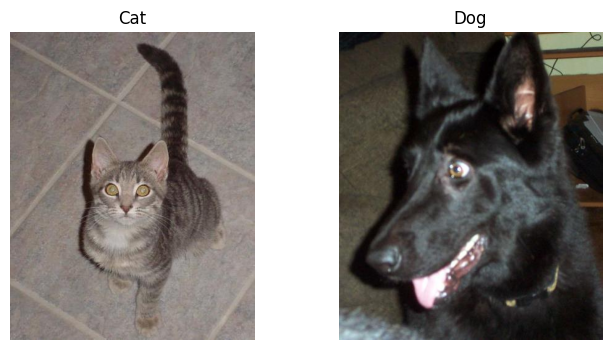

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

cat_image = load_img(train_dir + "/cats/" + os.listdir(train_dir + "/cats")[0])
dog_image = load_img(train_dir + "/dogs/" + os.listdir(train_dir + "/dogs")[0])

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(cat_image)
plt.title("Cat")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(dog_image)
plt.title("Dog")
plt.axis("off")


plt.show()

## 3. Data Preprocessing and Augmentation

The images are resized to 224 × 224 pixels and rescaled so that pixel values are between 0 and 1. Data augmentation is applied only to the training set to increase image variability and improve model generalization. The augmentation includes rotation, horizontal and vertical shifts, and horizontal flipping. Validation and test images are only rescaled and are not augmented.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

validation_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

validation_generator = validation_datagen.flow_from_directory(
    validation_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 19943 images belonging to 2 classes.
Found 2492 images belonging to 2 classes.
Found 2495 images belonging to 2 classes.


## 4. Transfer Learning with MobileNetV2

MobileNetV2 pretrained on ImageNet is used as the base model for transfer learning. The original classification head is removed using `include_top=False`, and the base model is initially frozen so that its pretrained feature-extraction weights are preserved. A new classification head is added for binary classification of cats and dogs.

In [ ]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## 5. Initial Model Training and Evaluation

The transfer-learning model is trained for 5 epochs while the pretrained MobileNetV2 base remains frozen. After training, the model is evaluated on the unseen test dataset to measure its generalization performance. The initial model achieved a test accuracy of 97.76% with a test loss of 0.0634.

In [ ]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=5
)

Epoch 1/5
624/624 ━━━━━━━━━━━━━━━━━━━━ 298s 464ms/step - accuracy: 0.9565 - loss: 0.1117 - val_accuracy: 0.9864 - val_loss: 0.0450
Epoch 2/5
624/624 ━━━━━━━━━━━━━━━━━━━━ 259s 415ms/step - accuracy: 0.9726 - loss: 0.0722 - val_accuracy: 0.9791 - val_loss: 0.0523
Epoch 3/5
624/624 ━━━━━━━━━━━━━━━━━━━━ 262s 420ms/step - accuracy: 0.9739 - loss: 0.0660 - val_accuracy: 0.9880 - val_loss: 0.0364
Epoch 4/5
624/624 ━━━━━━━━━━━━━━━━━━━━ 270s 433ms/step - accuracy: 0.9744 - loss: 0.0678 - val_accuracy: 0.9751 - val_loss: 0.0616
Epoch 5/5
624/624 ━━━━━━━━━━━━━━━━━━━━ 264s 422ms/step - accuracy: 0.9745 - loss: 0.0663 - val_accuracy: 0.9803 - val_loss: 0.0490


In [ ]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

53/78 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.9599 - loss: 0.1083

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 219ms/step - accuracy: 0.9776 - loss: 0.0634
Test Loss: 0.06340153515338898
Test Accuracy: 0.9775550961494446


In [ ]:
model.save("/content/drive/MyDrive/CNN_Assignment/mobilenet_cat_dog.keras")

## 6. Fine-Tuning

To improve the pretrained model, the final 30 layers of MobileNetV2 are unfrozen while the earlier layers remain frozen. The model is then recompiled using a small learning rate of 1e-5 to make gradual adjustments to the pretrained weights. After fine-tuning for 3 additional epochs, the test accuracy improved from 97.76% to 98.44%, and the test loss decreased from 0.0634 to 0.0464.

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
fine_tune_history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=3
)

Epoch 1/3
624/624 ━━━━━━━━━━━━━━━━━━━━ 300s 454ms/step - accuracy: 0.9448 - loss: 0.1424 - val_accuracy: 0.9783 - val_loss: 0.0572
Epoch 2/3
624/624 ━━━━━━━━━━━━━━━━━━━━ 267s 427ms/step - accuracy: 0.9659 - loss: 0.0903 - val_accuracy: 0.9811 - val_loss: 0.0489
Epoch 3/3
624/624 ━━━━━━━━━━━━━━━━━━━━ 269s 431ms/step - accuracy: 0.9710 - loss: 0.0710 - val_accuracy: 0.9852 - val_loss: 0.0360


In [ ]:
fine_tune_test_loss, fine_tune_test_accuracy = model.evaluate(test_generator)

print("Fine-tuned Test Loss:", fine_tune_test_loss)
print("Fine-tuned Test Accuracy:", fine_tune_test_accuracy)

78/78 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - accuracy: 0.9844 - loss: 0.0464
Fine-tuned Test Loss: 0.04644600674510002
Fine-tuned Test Accuracy: 0.9843687415122986


In [ ]:
model.save("/content/drive/MyDrive/CNN_Assignment/mobilenet_cat_dog_finetuned.keras")

## 7. Custom ImageLoader

A custom `ImageLoader` is implemented to satisfy the assignment requirement of training without directly using Keras or TensorFlow DataGenerator/DataLoader functions. The loader reads images in batches and performs on-the-fly preprocessing and augmentation during training. Four augmentation methods are included: horizontal flipping, rotation, brightness adjustment, and contrast adjustment.

In [ ]:
import numpy as np
import random
from PIL import Image, ImageOps, ImageEnhance

In [ ]:
def ImageLoader(folder_path, image_size=(224, 224)):
    images = []
    labels = []

    for class_name, label in [("cats", 0), ("dogs", 1)]:
        class_folder = os.path.join(folder_path, class_name)

        for filename in os.listdir(class_folder):
            image_path = os.path.join(class_folder, filename)

            try:
                img = Image.open(image_path).convert("RGB")
                img = img.resize(image_size)

                images.append(np.array(img))
                labels.append(label)

            except:
                pass

    return np.array(images), np.array(labels)

In [ ]:
def ImageLoader(folder_path, image_size=(224, 224), augment=False):
    images = []
    labels = []

    for class_name, label in [("cats", 0), ("dogs", 1)]:
        class_folder = os.path.join(folder_path, class_name)

        for filename in os.listdir(class_folder):
            image_path = os.path.join(class_folder, filename)

            try:
                img = Image.open(image_path).convert("RGB")
                img = img.resize(image_size)

                if augment:
                    # 1. Horizontal flip
                    if random.random() > 0.5:
                        img = ImageOps.mirror(img)

                    # 2. Small rotation
                    angle = random.uniform(-20, 20)
                    img = img.rotate(angle)

                    # 3. Brightness adjustment
                    brightness = ImageEnhance.Brightness(img)
                    img = brightness.enhance(random.uniform(0.8, 1.2))

                    # 4. Contrast adjustment
                    contrast = ImageEnhance.Contrast(img)
                    img = contrast.enhance(random.uniform(0.8, 1.2))

                img = np.array(img) / 255.0

                images.append(img)
                labels.append(label)

            except:
                pass

    return np.array(images), np.array(labels)

In [ ]:
def ImageLoader(folder_path, batch_size=32, image_size=(224, 224), augment=False):
    file_paths = []
    labels = []

    for class_name, label in [("cats", 0), ("dogs", 1)]:
        class_folder = os.path.join(folder_path, class_name)

        for filename in os.listdir(class_folder):
            file_paths.append(os.path.join(class_folder, filename))
            labels.append(label)

    while True:
        indices = np.arange(len(file_paths))
        np.random.shuffle(indices)

        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start:start + batch_size]

            batch_images = []
            batch_labels = []

            for i in batch_indices:
                try:
                    img = Image.open(file_paths[i]).convert("RGB")
                    img = img.resize(image_size)

                    if augment:
                        # 1. Horizontal flip
                        if random.random() > 0.5:
                            img = ImageOps.mirror(img)

                        # 2. Rotation
                        img = img.rotate(random.uniform(-20, 20))

                        # 3. Brightness
                        img = ImageEnhance.Brightness(img).enhance(
                            random.uniform(0.8, 1.2)
                        )

                        # 4. Contrast
                        img = ImageEnhance.Contrast(img).enhance(
                            random.uniform(0.8, 1.2)
                        )

                    img = np.array(img, dtype=np.float32) / 255.0

                    batch_images.append(img)
                    batch_labels.append(labels[i])

                except:
                    pass

            yield np.array(batch_images), np.array(batch_labels)

In [ ]:
custom_train_loader = ImageLoader(
    train_dir,
    batch_size=32,
    image_size=(224, 224),
    augment=True
)

sample_images, sample_labels = next(custom_train_loader)

print("Batch image shape:", sample_images.shape)
print("Batch label shape:", sample_labels.shape)
print("First 10 labels:", sample_labels[:10])

Batch image shape: (32, 224, 224, 3)
Batch label shape: (32,)
First 10 labels: [0 1 0 1 1 1 0 1 1 0]


## 8. Custom ImageLoader Model Training

A new MobileNetV2 transfer-learning model is created for the custom ImageLoader experiment so that this workflow can be evaluated independently from the standard Keras ImageDataGenerator approach. The pretrained base model is initially frozen, and a new binary classification head is added. The model is then trained using batches produced by the custom ImageLoader.

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense

custom_base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

custom_base_model.trainable = False

custom_model = Sequential([
    custom_base_model,
    GlobalAveragePooling2D(),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

In [ ]:
custom_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
custom_validation_loader = ImageLoader(
    validation_dir,
    batch_size=32,
    image_size=(224, 224),
    augment=False
)

In [ ]:
steps_per_epoch = len(os.listdir(train_dir + "/cats")) + len(os.listdir(train_dir + "/dogs"))
steps_per_epoch = steps_per_epoch // 32

validation_steps = len(os.listdir(validation_dir + "/cats")) + len(os.listdir(validation_dir + "/dogs"))
validation_steps = validation_steps // 32

custom_history = custom_model.fit(
    custom_train_loader,
    validation_data=custom_validation_loader,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=5
)

Epoch 1/5
623/623 ━━━━━━━━━━━━━━━━━━━━ 148s 222ms/step - accuracy: 0.9560 - loss: 0.1139 - val_accuracy: 0.9842 - val_loss: 0.0486
Epoch 2/5
623/623 ━━━━━━━━━━━━━━━━━━━━ 128s 206ms/step - accuracy: 0.9705 - loss: 0.0760 - val_accuracy: 0.9866 - val_loss: 0.0448
Epoch 3/5
623/623 ━━━━━━━━━━━━━━━━━━━━ 127s 205ms/step - accuracy: 0.9728 - loss: 0.0704 - val_accuracy: 0.9894 - val_loss: 0.0362
Epoch 4/5
623/623 ━━━━━━━━━━━━━━━━━━━━ 131s 210ms/step - accuracy: 0.9741 - loss: 0.0701 - val_accuracy: 0.9882 - val_loss: 0.0401
Epoch 5/5
623/623 ━━━━━━━━━━━━━━━━━━━━ 131s 211ms/step - accuracy: 0.9743 - loss: 0.0658 - val_accuracy: 0.9882 - val_loss: 0.0423


In [ ]:
custom_test_loader = ImageLoader(
    test_dir,
    batch_size=32,
    image_size=(224, 224),
    augment=False
)

test_steps = (
    len(os.listdir(test_dir + "/cats")) +
    len(os.listdir(test_dir + "/dogs"))
) // 32

custom_test_loss, custom_test_accuracy = custom_model.evaluate(
    custom_test_loader,
    steps=test_steps
)

print("Custom Loader Test Loss:", custom_test_loss)
print("Custom Loader Test Accuracy:", custom_test_accuracy)

77/77 ━━━━━━━━━━━━━━━━━━━━ 11s 147ms/step - accuracy: 0.9813 - loss: 0.0461
Custom Loader Test Loss: 0.04612622782588005
Custom Loader Test Accuracy: 0.9813311696052551


## 9. Custom Model Fine-Tuning

The custom ImageLoader model is fine-tuned by unfreezing the final 30 layers of MobileNetV2 while keeping the earlier layers frozen. The model is recompiled with a small learning rate of 1e-5 and trained for 3 additional epochs. After fine-tuning, the custom model achieved a test accuracy of 98.38% with a test loss of 0.0391, compared with 98.13% accuracy before fine-tuning.

In [ ]:
custom_base_model.trainable = True

for layer in custom_base_model.layers[:-30]:
    layer.trainable = False

In [ ]:
from tensorflow.keras.optimizers import Adam

custom_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
custom_fine_tune_history = custom_model.fit(
    custom_train_loader,
    validation_data=custom_validation_loader,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=3
)

Epoch 1/3
623/623 ━━━━━━━━━━━━━━━━━━━━ 155s 224ms/step - accuracy: 0.9450 - loss: 0.1396 - val_accuracy: 0.9829 - val_loss: 0.0389
Epoch 2/3
623/623 ━━━━━━━━━━━━━━━━━━━━ 140s 213ms/step - accuracy: 0.9646 - loss: 0.0878 - val_accuracy: 0.9882 - val_loss: 0.0355
Epoch 3/3
623/623 ━━━━━━━━━━━━━━━━━━━━ 130s 209ms/step - accuracy: 0.9704 - loss: 0.0763 - val_accuracy: 0.9890 - val_loss: 0.0312


In [ ]:
custom_ft_test_loss, custom_ft_test_accuracy = custom_model.evaluate(
    custom_test_loader,
    steps=test_steps
)

print("Fine-tuned Custom Test Loss:", custom_ft_test_loss)
print("Fine-tuned Custom Test Accuracy:", custom_ft_test_accuracy)

77/77 ━━━━━━━━━━━━━━━━━━━━ 11s 147ms/step - accuracy: 0.9838 - loss: 0.0391
Fine-tuned Custom Test Loss: 0.03910699859261513
Fine-tuned Custom Test Accuracy: 0.9837662577629089


In [ ]:
custom_model.save(
    "/content/drive/MyDrive/CNN_Assignment/custom_mobilenet_cat_dog_finetuned.keras"
)

## 10. Results and Comparison

The performance of the standard Keras ImageDataGenerator workflow and the custom ImageLoader workflow is compared using training/validation curves and final test accuracy. Fine-tuning improved both approaches. The standard fine-tuned MobileNetV2 achieved the highest test accuracy of 98.44%, while the fine-tuned custom ImageLoader model achieved a very similar accuracy of 98.38% and the lowest test loss of 0.0391.

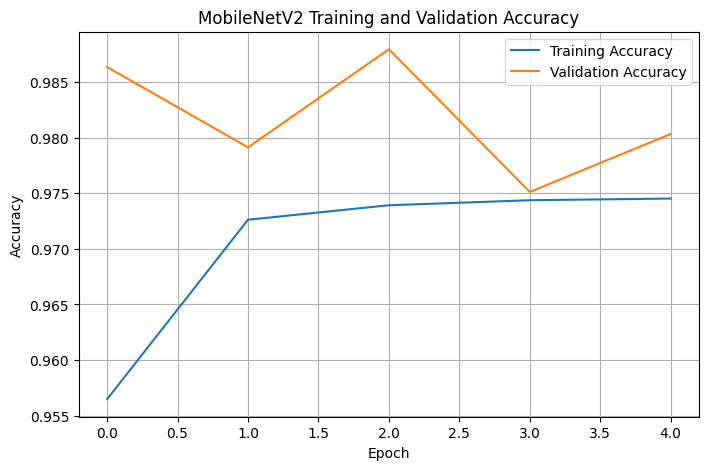

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('MobileNetV2 Training and Validation Accuracy')
plt.legend()
plt.grid(True)

plt.show()

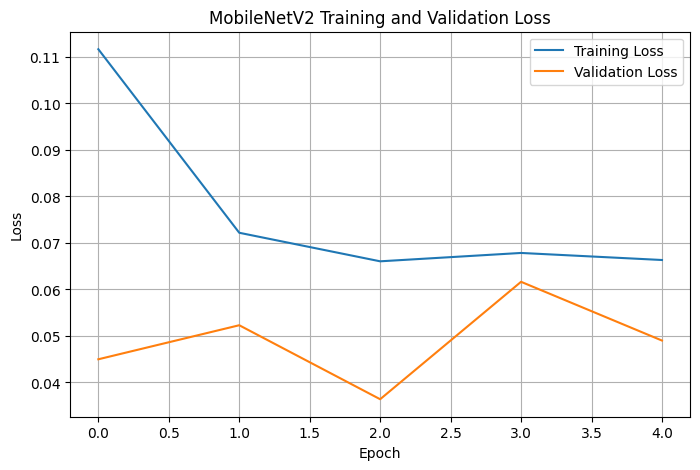

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('MobileNetV2 Training and Validation Loss')
plt.legend()
plt.grid(True)

plt.show()

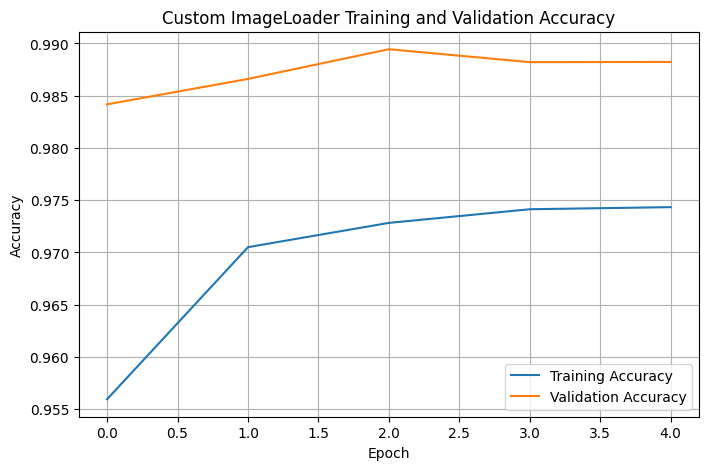

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(custom_history.history['accuracy'], label='Training Accuracy')
plt.plot(custom_history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Custom ImageLoader Training and Validation Accuracy')
plt.legend()
plt.grid(True)

plt.show()

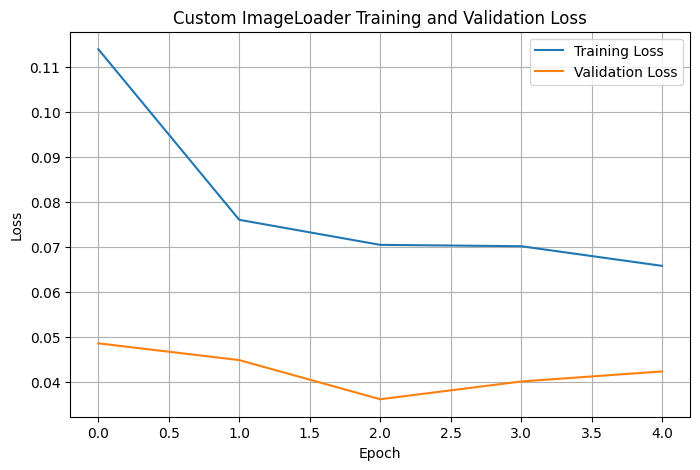

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(custom_history.history['loss'], label='Training Loss')
plt.plot(custom_history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Custom ImageLoader Training and Validation Loss')
plt.legend()
plt.grid(True)

plt.show()

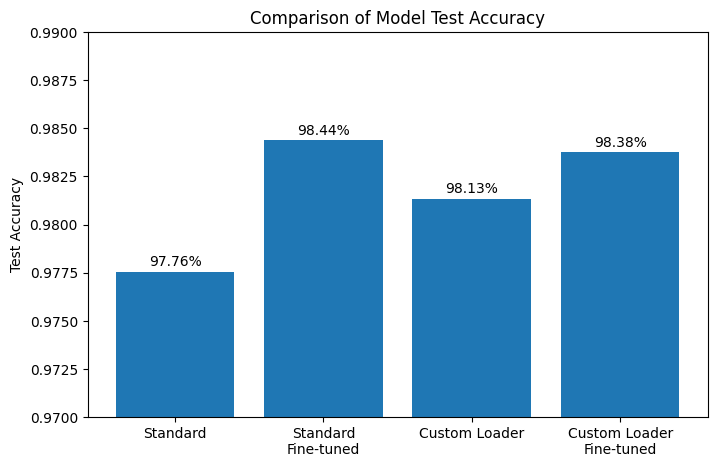

In [ ]:
model_names = [
    'Standard',
    'Standard\nFine-tuned',
    'Custom Loader',
    'Custom Loader\nFine-tuned'
]

test_accuracies = [
    0.9775550961494446,
    0.9843687415122986,
    0.9813311696052551,
    0.9837662577629089
]

plt.figure(figsize=(8,5))
bars = plt.bar(model_names, test_accuracies)

plt.ylabel('Test Accuracy')
plt.title('Comparison of Model Test Accuracy')
plt.ylim(0.97, 0.99)

for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        accuracy + 0.0003,
        f'{accuracy*100:.2f}%',
        ha='center'
    )

plt.show()

## 11. Hyperparameter Selection
- **Image size (224 × 224):** This size was selected because MobileNetV2 is commonly used with 224 × 224 RGB images and it provides a good balance between image detail and computational cost.

- **Batch size (32):** A batch size of 32 provides a practical balance between training stability, memory usage, and computational efficiency.

- **Optimizer (Adam):** Adam was selected because it adapts the learning rate during training and generally provides efficient convergence for deep learning models.

- **Loss function (Binary Cross-Entropy):** Binary cross-entropy was used because this is a binary classification problem with two classes: cats and dogs.

- **Initial epochs (5):** Five epochs were used for the initial transfer-learning stage because the pretrained MobileNetV2 already contains useful image features and therefore does not require extensive initial training.

- **Fine-tuning learning rate (1e-5):** A small learning rate was selected during fine-tuning to make small adjustments to the pretrained weights without significantly disrupting the features already learned from ImageNet.

- **Fine-tuning layers (last 30 layers):** Only the final 30 layers of MobileNetV2 were unfrozen. This allows higher-level features to adapt to the cats-versus-dogs classification task while preserving the more general features learned in earlier layers.

- **Dropout (0.2):** A dropout rate of 0.2 was included to reduce the risk of overfitting.

- **Data augmentation:** Augmentation was used to increase variability in the training data and improve generalization. The custom ImageLoader implemented horizontal flipping, rotation, brightness adjustment, and contrast adjustment.

## 12. TensorBoard Visualization

TensorBoard is used as an additional visualization tool to monitor model performance. Training and validation metrics, including accuracy and loss, are recorded using the TensorBoard callback and displayed interactively. This provides an additional way to inspect the model's training behavior and satisfies the optional TensorBoard bonus component of the assignment.

In [ ]:
import datetime

log_dir = "/content/drive/MyDrive/CNN_Assignment/logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

In [ ]:
from tensorflow.keras.callbacks import TensorBoard

tensorboard_callback = TensorBoard(
    log_dir=log_dir,
    histogram_freq=1
)

In [ ]:
tensorboard_history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=1,
    callbacks=[tensorboard_callback]
)

624/624 ━━━━━━━━━━━━━━━━━━━━ 277s 443ms/step - accuracy: 0.9717 - loss: 0.0718 - val_accuracy: 0.9852 - val_loss: 0.0384


In [ ]:
%load_ext tensorboard
%tensorboard --logdir "/content/drive/MyDrive/CNN_Assignment/logs"

Output hidden; open in https://colab.research.google.com to view.